# Foreign guests' seasons in Europe — all tourist accommodation

## Summary

| Question | Observation |
|---|---|
| **Overview (as in Eurostat's article)** | The two busiest months hold 31.3% of the EU-27's nights in 2024 (Eurostat: 31%); in the median NUTS 2 region 28%, and over 40% in 43 regions — the Romanian and Bulgarian Black Sea coast, Calabria and the Croatian coast above 55%. August is the busiest month in 182 of 265 regions and July in 60; winter peaks are limited to the Alps, Sofia's region, Vienna (December) and the Caribbean overseas regions, and cities (Paris, Madrid, Belgrade, Bucharest) peak in May or October. The capital region is the least seasonal in 21 of 26 countries with several regions. Domestic and foreign guests share the same two busiest months in 63% of regions. At the peak, the Aegean and Ionian islands host 800–870 guests a night per 1,000 inhabitants and the Croatian coast 650; per km², Vienna, Brussels, Malta and Prague are the densest. |
| **How large is foreign demand, and where?** | Foreign guests spent 1.47 billion of 3.11 billion nights (47%) — far fewer than the 62% the platform data suggested. They are the majority in 18 of 34 countries, from 16–19% in Romania, Poland and Germany to over 90% in Croatia, Cyprus, Malta and Liechtenstein. Most regions are mainly domestic (167 of 268 under 40% foreign); the 31 mainly-foreign regions hold 21% of all nights but 39% of foreign nights, and the ten largest foreign destinations (Canarias, the Croatian coast, the Balearics, Cataluña, Veneto …) hold 36%. |
| **1. How seasonal is each country and region?** | Ranked by the Gini index of foreign nights, Croatia (0.61), Bulgaria and Greece (0.53) and Albania (0.45) lead; Serbia, Czechia, Romania and Poland (0.09–0.13) have the most even foreign year. Among regions, the Bulgarian Black Sea coast, the Croatian coast, Corse, northern Greece, the Aegean and Ionian islands and northern Albania are the most seasonal; Podkarpackie, Canarias, Brussels, Bucharest and Murcia the least. The S_R ÷ Gini ratio finds foreign demand split into **two seasons** in 11 regions — the Alps (Tirol, Salzburg, Vorarlberg, Ostschweiz, Rhône-Alpes, Valle d'Aosta), the Czech and Slovak mountains and Innlandet — and a main plus a secondary season in 19 more; Gini counts their busy months as if they were one season, so Austria ranks 15th by Gini but 31st by S_R. Among highly seasonal regions, the Greek islands combine a summer peak with an almost empty winter (peak-to-trough ratios of 200–1,500), while others keep a real off-season (ratio 6–7). |
| **2. What seasonal patterns are there?** | Five shapes of foreign demand: a **long summer season** May–October (92 regions; Balearics, Cataluña, Veneto; islands 1.8× over-represented), a **short summer peak** (91; the Croatian coast, northern Greece; rural regions 1.5×), **winter + summer seasons** (14; Tirol, Bolzano, Salzburg; inland mountain regions 6×), a pure **winter season** (2; northern and eastern Finland, Martinique) and **year-round** demand (66; Canarias, Île-de-France, Valencia; urban regions 1.6×). Size is measured separately: by Gini class 87 regions have high, 90 medium and 88 low seasonality. 89% keep their shape from 2023 to 2024, but the summer shapes form a continuum, and foreign and domestic guests share the same shape in only half the regions. |
| **3. Do foreign guests stabilise or sharpen the regional season?** | *Three classes (timing counterfactual on Gini):* foreign timing sharpens the season in 125 of 264 regions, smooths it in 50 and has no clear effect in 89; the typical effect is small (+0.006 Gini against a typical Gini of 0.21; +0.016 weighted by nights) but large where foreign guests dominate (median +0.079, 77% sharpened). *Four types (relative marginal effect of the Gini decomposition, Fernández-Morales et al. 2016):* in 140 regions with half of all nights, foreign demand is **peak-reinforcing**; in 54 (17% of nights) it is **flatter** than the region's — a lasting stabiliser (Algarve, Bolzano, Madeira, Valencia); only 6 regions (Valle d'Aosta, Małopolskie, Arnsberg …) show the paper's **off-peak compensation**, where seasonal foreign demand fills the region's quiet months; 64 are **neutral**, including the islands where foreign guests are over 90% of nights and simply *are* the season. |
| **What goes with seasonal foreign demand?** | Coastal and rural regions: a fully rural region has a foreign Gini about 0.4 higher than a fully urban one, a fully coastal region 0.12–0.21 higher than an inland one, within and across countries. Islands and inland mountains add nothing beyond that; larger foreign volumes go with slightly more seasonality, but within countries the link is weak. |

##### Data 
Eurostat `tour_occ_nin2m`: nights in hotels, holiday and short-stay accommodation and campsites (NACE 55.1–55.3); 34 countries (EU-27, EFTA and the candidate countries North Macedonia, Albania and Serbia), NUTS 2 regions, **2023–2024**. Seasonality is measured on **nights per day** (month length removed) and on the **2023–2024 average profile**; single years are used to check stability. The indices are computed in this notebook; their full definitions and robustness checks are in `Stage 2 Indices.ipynb`.

##### Main measure
**The Gini index** — the standard measure in tourism research — shows how concentrated demand is in time and can be split into the contributions of domestic and foreign guests. **S_R** (Lo Magno, Ferrante & De Cantis 2017) accounts for which months are busy; it is used alongside, and the ratio S_R ÷ Gini shows whether a region has one season or two.

## Setup

In [1]:
import json

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import LineCollection, PathCollection
from matplotlib.patches import Patch
from matplotlib.path import Path
from scipy import stats
from scipy.cluster.hierarchy import fcluster, linkage

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

lg = pd.read_csv("data/transformed/tour_occ_nin2m_long.csv",
                 encoding="utf-8-sig",
                 keep_default_na=False,
                 na_values=[""])

MONTH_NAMES = [
    "January", "February", "March", "April", "May", "June", "July", "August",
    "September", "October", "November", "December"
]
SHORT = [m[:3] for m in MONTH_NAMES]
EU_CC = [
    "BE", "BG", "CZ", "DK", "DE", "EE", "IE", "EL", "ES", "FR", "HR", "IT",
    "CY", "LV", "LT", "LU", "HU", "MT", "NL", "AT", "PL", "PT", "RO", "SI",
    "SK", "FI", "SE"
]
# NUTS 2 region of the capital city
CAPITAL = {
    "BE": "BE10",
    "BG": "BG41",
    "CZ": "CZ01",
    "DK": "DK01",
    "DE": "DE30",
    "EE": "EE00",
    "IE": "IE06",
    "EL": "EL30",
    "ES": "ES30",
    "FR": "FR10",
    "HR": "HR05",
    "IT": "ITI4",
    "CY": "CY00",
    "LV": "LV00",
    "LT": "LT01",
    "LU": "LU00",
    "HU": "HU11",
    "MT": "MT00",
    "NL": "NL32",
    "AT": "AT13",
    "PL": "PL91",
    "PT": "PT1A",
    "RO": "RO32",
    "SI": "SI04",
    "SK": "SK01",
    "FI": "FI1B",
    "SE": "SE11",
    "IS": "IS00",
    "LI": "LI00",
    "NO": "NO08",
    "CH": "CH02",
    "MK": "MK00",
    "AL": "AL02",
    "RS": "RS11"
}

# Region attributes (one row per region)
REG = lg.drop_duplicates("NUTSCode").set_index("NUTSCode")[[
    "Region", "NUTSLevel", "Country", "AreaKm2", "PrcRural", "PrcCoastal",
    "PrcInlandMountain", "PrcIsland"
]]
CC_NAME = {c[:2]: n for c, n in REG[REG["NUTSLevel"] == 0]["Country"].items()}
EU27 = [CC_NAME[c] for c in EU_CC]
POP = lg.drop_duplicates(["NUTSCode",
                          "Year"]).set_index(["NUTSCode",
                                              "Year"])["Population"]

# Monthly series: one row per region x guest group x year, the 12 months as columns
KEY = ["NUTSCode", "ResidenceCountry", "Year"]
M = lg[lg["Month"] != "Total"]
NIGHTS = M.pivot_table(index=KEY, columns="Month",
                       values="Value").reindex(columns=MONTH_NAMES)
NPD = M.pivot_table(index=KEY, columns="Month", values="NightsPerDay").reindex(
    columns=MONTH_NAMES)  # nights per day
ANNUAL = lg[lg["Month"] == "Total"].set_index(KEY)["Value"]
FLAGS = M.assign(C=M["Flag"].eq("C"),
                 u=M["Flag"].eq("u")).groupby(KEY)[["C", "u"]].any()

# Colours, chart style, maps
INK, MUTED, GRIDC = "#0b0b0b", "#52514e", "#e4e3df"
COLOR = {"Domestic": "#2a78d6", "Foreign": "#eb6834", "Total": "#1baf7a"}


def style(ax, title, ylabel=None):
    ax.set_title(title, loc="left", color=INK, fontsize=12)
    if ylabel:
        ax.set_ylabel(ylabel, color=MUTED)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.tick_params(colors=MUTED)
    ax.grid(axis="y", color=GRIDC, lw=0.8)
    ax.set_axisbelow(True)


# Region outlines: Eurostat GISCO NUTS 2024 (1:20 million, ETRS89-LAEA), via Nuts2json - data/raw/geo/
def _geom_path(g):
    rings = [
        r for poly in (g["coordinates"] if g["type"] ==
                       "MultiPolygon" else [g["coordinates"]]) for r in poly
    ]
    verts, codes = [], []
    for ring in rings:
        verts += ring + [ring[0]]
        codes += [Path.MOVETO
                  ] + [Path.LINETO] * (len(ring) - 1) + [Path.CLOSEPOLY]
    return Path(verts, codes)


_load = lambda f: json.load(open(f"data/raw/geo/{f}", encoding="utf-8"))[
    "features"]
MAP_REGIONS = {
    f["properties"]["id"]: _geom_path(f["geometry"])
    for f in _load("nutsrg_2.json")
}
MAP_LAND = [_geom_path(f["geometry"]) for f in _load("cntrg.json")]
MAP_BORDERS = [
    line for f in _load("nutsbn_0.json") if f["properties"].get("co") == "F"
    for line in (f["geometry"]["coordinates"] if f["geometry"]["type"] ==
                 "MultiLineString" else [f["geometry"]["coordinates"]])
]


def region_map(colors, legend, title, note=None):
    """Choropleth of NUTS 2 regions. colors: NUTSCode -> colour; legend: list of (label, colour). Grey = no data."""
    fig, ax = plt.subplots(figsize=(8, 8.2), dpi=110)
    ax.add_collection(
        PathCollection(MAP_LAND,
                       facecolor="#f1f1ef",
                       edgecolor="white",
                       lw=0.3,
                       zorder=1))
    ids = list(MAP_REGIONS)
    ax.add_collection(
        PathCollection([MAP_REGIONS[i] for i in ids],
                       facecolor=[colors.get(i, "#c9cbd1") for i in ids],
                       edgecolor="white",
                       lw=0.25,
                       zorder=2))
    ax.add_collection(
        LineCollection(MAP_BORDERS, colors="white", lw=0.9, zorder=3))
    ax.set_xlim(1.85e6, 6.6e6)
    ax.set_ylim(0.9e6, 5.45e6)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.legend(handles=[
        Patch(facecolor=c, edgecolor="none", label=l) for l, c in legend
    ] + [Patch(facecolor="#c9cbd1", edgecolor="none", label="no data")],
              frameon=False,
              fontsize=8,
              loc="upper right",
              title=note,
              title_fontsize=8,
              alignment="left")
    plt.tight_layout()
    plt.show()
    off = sorted(set(colors) - set(ids))
    if off:
        print("not on this map (Azores, Madeira, French overseas regions):",
              off)


def binned_map(values, cuts, labels, cmap, title, note):
    """Map of a numeric indicator in classes."""
    cols = [
        matplotlib.colors.to_hex(c)
        for c in cmap(np.linspace(0.2, 0.95, len(labels)))
    ]
    cls = pd.cut(values.dropna(), cuts, labels=labels, right=False)
    region_map({k: cols[labels.index(v)]
                for k, v in cls.items()}, [(f"{l} ({(cls == l).sum()})", c)
                                           for l, c in zip(labels, cols)],
               title, note)


print(
    f"{lg['Country'].nunique()} countries, {(REG['NUTSLevel'] == 2).sum()} NUTS 2 regions, years {sorted(lg['Year'].unique())}"
)

34 countries, 268 NUTS 2 regions, years [2023, 2024]


### Which series are used

A series (one region, one guest group, one year) is used when all **12 months are published**, **none is confidential** (Eurostat flag `C`) and it has at least **10,000 nights** — the floor below which small series jump around from year to year. This removes only Liechtenstein's guest groups and three French overseas regions. Months flagged **`u` (low reliability)** are kept and marked.

In [2]:
USABLE = NPD.notna().all(
    axis=1) & ~FLAGS["C"] & (ANNUAL.reindex(NPD.index) >= 10_000)
LOWREL = FLAGS["u"][USABLE].groupby(
    level=["NUTSCode", "ResidenceCountry"]).any()
NIGHTS_AVG = ANNUAL.reindex(NPD.index)[USABLE].groupby(
    level=["NUTSCode", "ResidenceCountry"]).mean()  # average annual nights


def pick(frame, guest, year=None, level=2):
    """Usable rows of a series table for one guest group (and year), at one NUTS level, indexed by NUTSCode."""
    f = frame[USABLE.reindex(
        frame.index,
        fill_value=False)] if "Year" in frame.index.names else frame
    f = f.xs(guest, level="ResidenceCountry")
    if year is not None:
        f = f.xs(year, level="Year")
    return f[f.index.map(REG["NUTSLevel"]) == level]


print(f"{int(USABLE.sum()):,} of {len(NPD):,} series usable")

2,377 of 2,389 series usable


## Overview of 2024

### The two busiest months hold almost a third of the year's nights

> **Top-2-month share** estimates how much of the year happens in the two busiest months.
> *Formula:* nights in the two busiest months ÷ nights in the year × 100, on monthly totals.
> *Read:* 16.7% = every month equal; 50% = half the year in two months.

For the EU-27 countries the top-2-month share in 2024 was **31.3%**.

EU-27, 2024: 31.3% of nights in the two busiest months (July + August)
NUTS-2 regions, 2024: 265; median share 28.2%; share 40% or more - in 43 regions


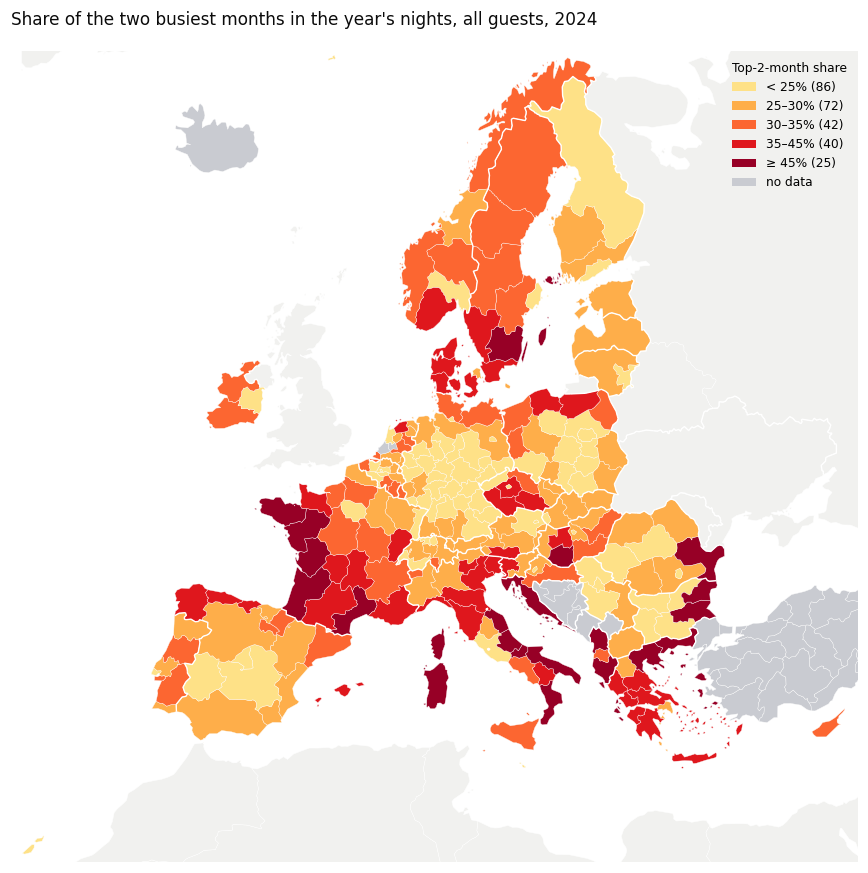

not on this map (Azores, Madeira, French overseas regions): ['FRY1', 'FRY2', 'FRY3', 'FRY4', 'FRY5', 'PT20', 'PT30']


In [3]:
def busiest(w):
    # Top-2-month share, busiest month and two busiest months of each row of 12 monthly values
    v = w.to_numpy()
    top = np.argsort(-v, axis=1)[:, :2]
    return pd.DataFrame(
        {
            "Top2Share":
            100 * np.take_along_axis(v, top, axis=1).sum(axis=1) /
            v.sum(axis=1),
            "TopMonth": [MONTH_NAMES[i] for i in top[:, 0]],
            "Top2Months":
            [" + ".join(MONTH_NAMES[j] for j in sorted(t)) for t in top]
        },
        index=w.index)


o24 = busiest(pick(NIGHTS, "Total", 2024)).join(REG)
eu = NIGHTS.xs(("Total", 2024),
               level=["ResidenceCountry",
                      "Year"]).reindex(EU_CC).sum().to_frame().T
print(
    f"EU-27, 2024: {busiest(eu)['Top2Share'].iloc[0]:.1f}% of nights in the two busiest months ({busiest(eu)['Top2Months'].iloc[0]})"
)
print(
    f"NUTS-2 regions, 2024: {len(o24)}; median share {o24['Top2Share'].median():.1f}%; share 40% or more - in {(o24['Top2Share'] >= 40).sum()} regions"
)
binned_map(
    o24["Top2Share"], [0, 25, 30, 35, 45, 101],
    ["< 25%", "25–30%", "30–35%", "35–45%", "≥ 45%"], plt.cm.YlOrRd,
    "Share of the two busiest months in the year's nights, all guests, 2024",
    "Top-2-month share")

### Most seasonal: coastal

You can see that the largest concentration appears in the **coastal** regions. However, if we take into account the **percentage of a region's residents** who actually live in coastal areas, it becomes clear that many such regions are just large, with a minority of the population residing at the coast (Languedoc-Roussillon, Aquitaine, Sud-Est). Out of the top 20 regions by 2-month concentration, only 6 are **predominantly coastal**.

In [4]:
top20 = o24.nlargest(20, "Top2Share")
display(top20[["Region", "Country", "Top2Share", "Top2Months",
               "PrcCoastal"]].round(1).reset_index(drop=True))
print(
    f"Of these 20, predominantly coastal (50%+ of residents in coastal municipalities): {(top20['PrcCoastal'] >= 50).sum()}"
)

,Region,Country,Top2Share,Top2Months,PrcCoastal
0,Sud-Est,Romania,66.0,July + August,17.0
1,Yugoiztochen,Bulgaria,60.1,July + August,29.3
2,Calabria,Italy,58.8,July + August,65.6
3,Jadranska Hrvatska,Croatia,57.7,July + August,82.5
4,Severoiztochen,Bulgaria,56.9,July + August,48.7
5,Languedoc-Roussillon,France,51.8,July + August,20.6
6,Veri,Albania,51.6,July + August,NaN
7,Aquitaine,France,50.4,July + August,16.9
8,Molise,Italy,50.1,July + August,20.1
9,Corse,France,50.0,July + August,88.5


Of these 20, predominantly coastal (50%+ of residents in coastal municipalities): 6


### Least seasonal: capital

In [5]:
top20s = o24.reset_index().groupby('Country').apply(
    lambda x: x.nsmallest(1, 'Top2Share')).reset_index()
top20s['Capital'] = [
    1 if ncode in list(CAPITAL.values()) else 0 for ncode in top20s['NUTSCode']
]
top20s['NRegions'] = top20s.Country.map(
    o24.reset_index().groupby('Country').NUTSCode.nunique().to_dict())

display(top20s[top20s['NRegions'] > 1][[
    "Region", "Country", "Top2Share", "Top2Months", "Capital"
]].round(2).sort_values(by=["Capital", "Country"],
                        ascending=[False, True]).reset_index(drop=True))
print(
    f"Out of {(top20s['NRegions'] > 1).sum()} countries, capital regions are the least seasonal in: {((top20s['Capital'] == 1) & (top20s['NRegions'] > 1)).sum()}"
)

,Region,Country,Top2Share,Top2Months,Capital
0,Qender,Albania,30.79,July + August,1
1,Wien,Austria,20.98,August + December,1
2,Région de Bruxelles-Capitale/Brussels Hoofdste...,Belgium,18.65,July + December,1
3,Yugozapaden,Bulgaria,20.95,February + August,1
4,Grad Zagreb,Croatia,20.62,August + September,1
5,Praha,Czechia,20.22,July + August,1
6,Hovedstaden,Denmark,25.47,July + August,1
7,Helsinki-Uusimaa,Finland,22.88,July + August,1
8,Ile de France,France,18.51,May + October,1
9,Berlin,Germany,19.21,July + August,1


Out of 26 countries, capital regions are the least seasonal in: 21


### August is the busiest month in most regions

busiest month, NUTS 2 regions, 2024: {'August': 182, 'July': 60, 'October': 7, 'February': 6, 'June': 4, 'May': 3, 'December': 1, 'September': 1, 'January': 1}


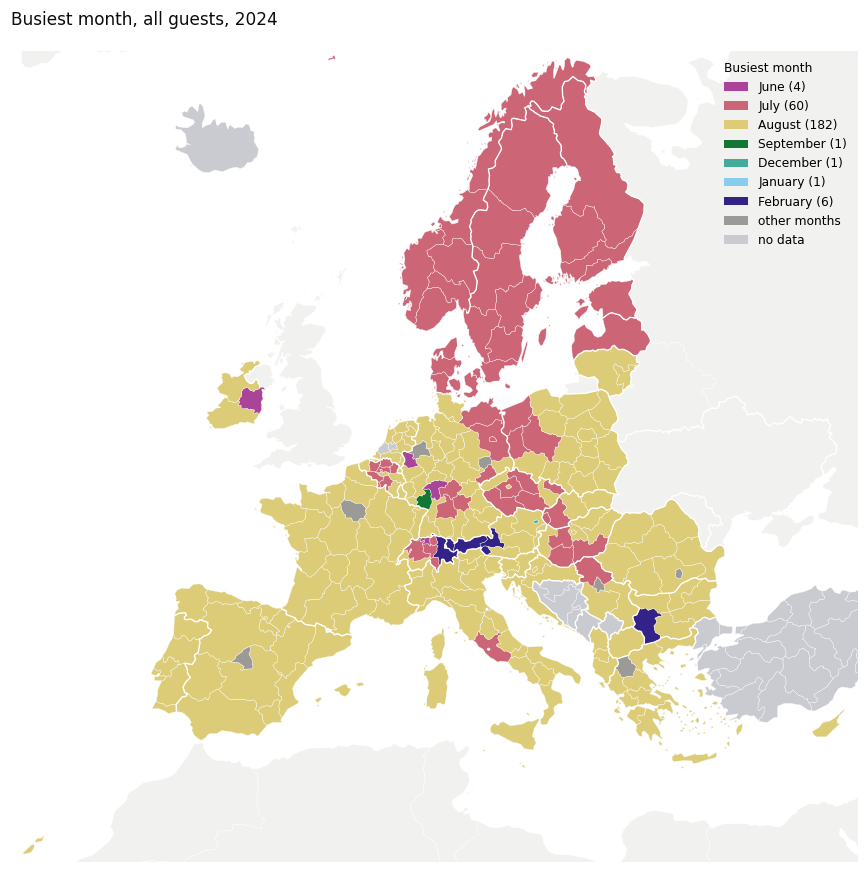

not on this map (Azores, Madeira, French overseas regions): ['FRY1', 'FRY2', 'FRY3', 'FRY4', 'FRY5', 'PT20', 'PT30']

Regions whose busiest month is NOT July-August:


,Region,Country,TopMonth,Top2Months,Top2Share
16,Martinique,France,January,January + February,23.322273
1,Salzburg,Austria,February,February + August,27.519324
2,Tirol,Austria,February,February + August,27.556958
3,Vorarlberg,Austria,February,February + August,27.467598
4,Yugozapaden,Bulgaria,February,February + August,20.950590
15,Guadeloupe,France,February,February + March,23.051389
6,Ostschweiz,Switzerland,February,February + August,27.068333
19,Mayotte,France,May,May + June,20.026487
11,Leipzig,Germany,May,May + August,20.327685
9,Münster,Germany,May,May + August,20.761946


In [6]:
MCOL = {
    "June": "#AA4499",
    "July": "#CC6677",
    "August": "#DDCC77",
    "September": "#117733",
    "December": "#44AA99",
    "January": "#88CCEE",
    "February": "#332288",
    "March": "#b7d5ef"
}
tm = o24["TopMonth"]
print("busiest month, NUTS 2 regions, 2024:", tm.value_counts().to_dict())
region_map({k: MCOL.get(v, "#9b9a96")
            for k, v in tm.items()},
           [(f"{m} ({(tm == m).sum()})", c)
            for m, c in MCOL.items() if (tm == m).any()] +
           ([("other months", "#9b9a96")] if
            (~tm.isin(list(MCOL))).any() else []),
           "Busiest month, all guests, 2024", "Busiest month")
print()

o24["TopMonth"] = pd.Categorical(o24["TopMonth"], categories=MONTH_NAMES, ordered=True)   
print("Regions whose busiest month is NOT July-August:")
display(o24[~tm.isin(["July", "August"])][[
    "Region", "Country", "TopMonth", "Top2Months", "Top2Share"
]].reset_index(drop=True).sort_values(by=["TopMonth", "Country", "Region"]))

### Where do the domestic and foreign peaks coincide, and where are they furthest apart?

**63%** of EU regions share the same seasonal two-month peak, but only **51%** share the exact same top month. Eleven regions show a **5-to-6-month difference** between their domestic and foreign tourist peaks. In 8 out of those 11 cases, domestic guest arrivals peak in the summer, while foreign arrivals peak in the winter. Conversely, two regions in Switzerland experience the exact opposite situation. For Île-de-France, the variance is due to an overall prolonged season, as it is the one with the capital and the least seasonal of all French regions.

In [7]:
d24, f24 = busiest(pick(NIGHTS, "Domestic",
                        2024)).join(REG), busiest(pick(NIGHTS, "Foreign",
                                                       2024)).join(REG)
both = d24.index.intersection(f24.index)
print(f"Out of {len(both)} regions:")
print(
    f"{(d24.loc[both, 'Top2Months'] == f24.loc[both, 'Top2Months']).mean():.0%} share two busiest months for domestic and foreign guests"
)
print(
    f"{(d24.loc[both, 'TopMonth'] == f24.loc[both, 'TopMonth']).mean():.0%} share top busiest month for domestic and foreign guests"
)
print()
d24["TopMonth"] = pd.Categorical(d24["TopMonth"],
                                 categories=MONTH_NAMES,
                                 ordered=True)
f24["TopMonth"] = pd.Categorical(f24["TopMonth"],
                                 categories=MONTH_NAMES,
                                 ordered=True)

topm = d24[['Region', 'Country',
            'TopMonth']].rename(columns={
                'TopMonth': 'TopMonthDomestic'
            }).join(f24[['TopMonth'
                         ]].rename(columns={'TopMonth': 'TopMonthForeign'}))
topm['TopMonthFn'] = pd.to_datetime(topm['TopMonthForeign'],
                                    format='%B').dt.month
topm['TopMonthDn'] = pd.to_datetime(topm['TopMonthDomestic'],
                                    format='%B').dt.month
topm['DistanceBwTops'] = [
    min((xf - xd) % 12, 12 - ((xf - xd) % 12))
    for xf, xd in zip(topm['TopMonthFn'], topm['TopMonthDn'])
]

print(
    "Distance between top busiest months for domestic and foreign guests (0 = they share same top month):"
)
display(topm.reset_index()[["Region", "DistanceBwTops"
                            ]].groupby("DistanceBwTops").agg('nunique').rename(
                                columns={'Region': 'NumberOfRegions'}))
print()
print("Top months shared by domestic and foreign guests:")
display(topm[topm["DistanceBwTops"] == 0].reset_index()[[
    "Region", "TopMonthDomestic"
]].groupby("TopMonthDomestic").agg('nunique').rename(
    columns={'Region': 'NumberOfRegions'}))
print()
print(
    "Regions with the 5-6-month distance between domestic and foreign peaks:")
display(topm[topm['DistanceBwTops'] >= 5].reset_index()[[
    "Region", "Country", "TopMonthDomestic", "TopMonthForeign",
    "DistanceBwTops"
]].sort_values(by=["DistanceBwTops", "TopMonthDomestic", "Country"],
               ascending=[False, True, True]).reset_index(drop=True))

Out of 260 regions:
63% share two busiest months for domestic and foreign guests
51% share top busiest month for domestic and foreign guests

Distance between top busiest months for domestic and foreign guests (0 = they share same top month):


,NumberOfRegions
DistanceBwTops,
0,132
1,89
2,14
3,11
4,3
5,5
6,6



Top months shared by domestic and foreign guests:


,NumberOfRegions
TopMonthDomestic,
February,1
June,2
July,28
August,100
October,1



Regions with the 5-6-month distance between domestic and foreign peaks:


,Region,Country,TopMonthDomestic,TopMonthForeign,DistanceBwTops
0,Région lémanique,Switzerland,February,August,6
1,Ostschweiz,Switzerland,February,August,6
2,Tirol,Austria,August,February,6
3,Vorarlberg,Austria,August,February,6
4,Yugozapaden,Bulgaria,August,February,6
5,Valle d’Aosta/Vallée d’Aoste,Italy,August,February,6
6,Severovýchod,Czechia,July,February,5
7,Pohjois- ja Itä-Suomi,Finland,July,December,5
8,Yuzhen tsentralen,Bulgaria,August,January,5
9,Canarias,Spain,August,March,5


### Pressure at the peak: tourism intensity and density

> **Peak-month intensity and density** estimate how many guests does a place host at the height
> of its season, relative to its residents and to its land.
> *Formula:* nights per day in the busiest month ÷ inhabitants × 1,000 (intensity); ÷ km² (density).
> *Read:* 100 = one guest for every ten residents on a typical night of the peak month.
> Both count only nights in rented accommodation (no day visitors, second homes or stays with friends), so they understate the real pressure.

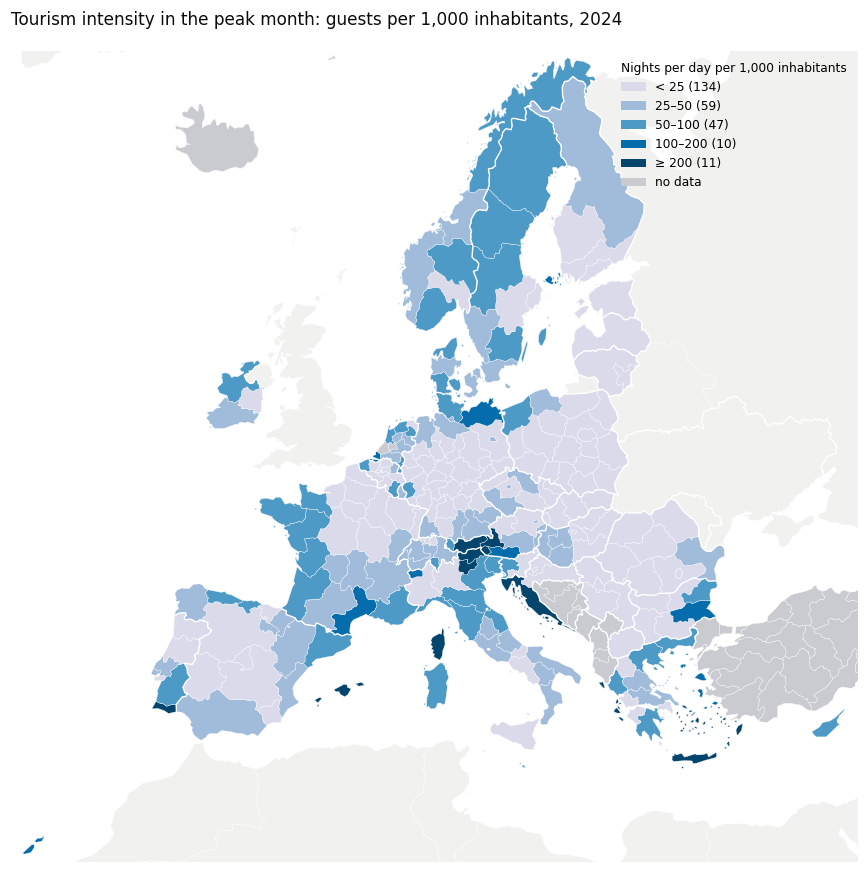

not on this map (Azores, Madeira, French overseas regions): ['FRY1', 'FRY2', 'FRY3', 'FRY4', 'FRY5', 'PT20', 'PT30']

Highest intensity:


,Region,Country,TopMonth,PeakIntensity,PeakDensity,Top2Share
0,Notio Aigaio,Greece,August,868.9,53.4,41.8
1,Ionia Nisia,Greece,August,801.9,69.7,46.9
2,Jadranska Hrvatska,Croatia,August,650.8,34.5,57.7
3,Kriti,Greece,August,367.4,27.4,39.8
4,Provincia Autonoma di Bolzano/Bozen,Italy,August,361.7,26.3,29.9
5,Illes Balears,Spain,August,354.9,87.6,35.8
6,Corse,France,August,271.6,11.2,50.0
7,Tirol,Austria,February,254.6,15.6,27.6
8,Algarve,Portugal,August,248.5,24.1,29.9
9,Provincia Autonoma di Trento,Italy,August,221.6,19.5,35.5


no population for: ['AL01', 'AL02', 'AL03', 'NO0B']


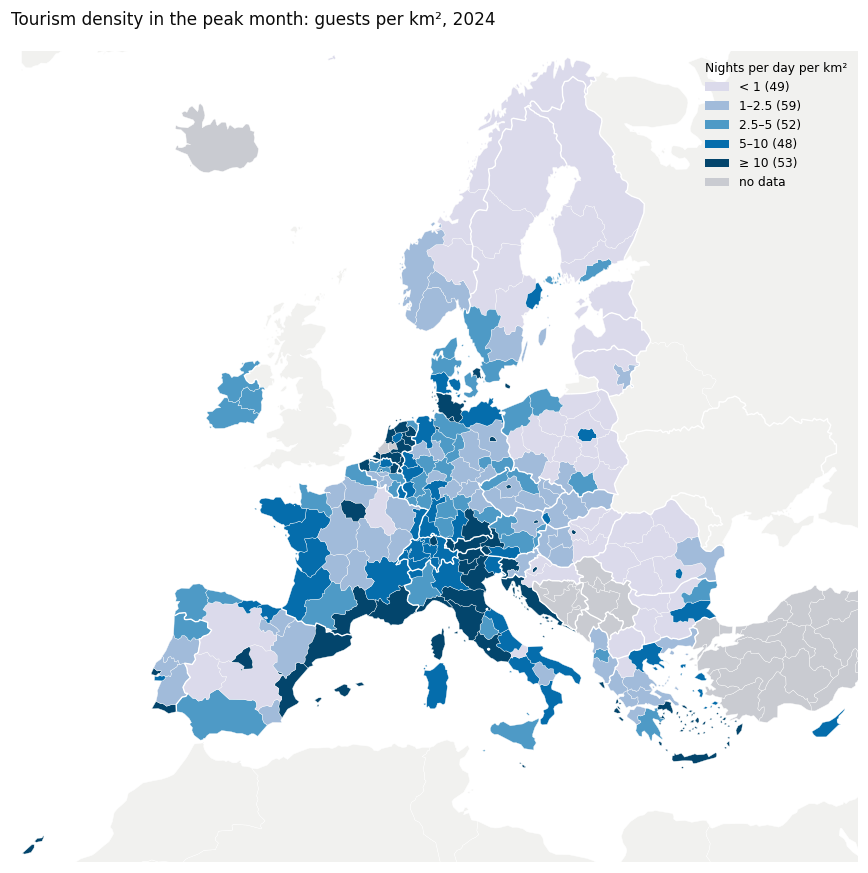

not on this map (Azores, Madeira, French overseas regions): ['FRY1', 'FRY2', 'FRY3', 'FRY4', 'FRY5', 'PT20', 'PT30']

Highest density:


,Region,Country,TopMonth,PeakIntensity,PeakDensity,Top2Share
0,Wien,Austria,December,31.18,150.68,20.98
1,Région de Bruxelles-Capitale/Brussels Hoofdste...,Belgium,July,17.88,139.58,18.65
2,Malta,Malta,August,75.59,134.78,22.77
3,Praha,Czechia,August,43.32,120.93,20.22
4,Berlin,Germany,July,25.99,106.83,19.21
5,Illes Balears,Spain,August,354.88,87.60,35.82
6,Ionia Nisia,Greece,August,801.85,69.70,46.94
7,Budapest,Hungary,August,21.33,68.50,19.66
8,Hamburg,Germany,August,27.74,68.04,19.78
9,Notio Aigaio,Greece,August,868.86,53.39,41.81


In [8]:
w = pick(NIGHTS, "Total", 2024)
peak_day = pick(NPD, "Total", 2024).to_numpy()[np.arange(
    len(w)), w.to_numpy().argmax(axis=1)]  # nights per day, busiest month
o24["PeakIntensity"] = pd.Series(peak_day, index=w.index) / POP.xs(
    2024, level="Year").reindex(w.index) * 1000
o24["PeakDensity"] = pd.Series(peak_day,
                               index=w.index) / REG["AreaKm2"].reindex(w.index)
cols = [
    "Region", "Country", "TopMonth", "PeakIntensity", "PeakDensity",
    "Top2Share"
]
binned_map(
    o24["PeakIntensity"], [0, 25, 50, 100, 200, np.inf],
    ["< 25", "25–50", "50–100", "100–200", "≥ 200"], plt.cm.PuBu,
    "Tourism intensity in the peak month: guests per 1,000 inhabitants, 2024",
    "Nights per day per 1,000 inhabitants")
print()
print("Highest intensity:")
display(
    o24.nlargest(10, "PeakIntensity")[cols].round(1).reset_index(drop=True))
print("no population for:", sorted(o24.index[o24["PeakIntensity"].isna()]))
binned_map(o24["PeakDensity"], [0, 1, 2.5, 5, 10, np.inf],
           ["< 1", "1–2.5", "2.5–5", "5–10", "≥ 10"], plt.cm.PuBu,
           "Tourism density in the peak month: guests per km², 2024",
           "Nights per day per km²")
print()
print("Highest density:")
display(o24.nlargest(10, "PeakDensity")[cols].round(2).reset_index(drop=True))

## Foreign guests: overview

### Which demand dominates in EU countries and regions: domestic or foreign?

> **Foreign share**
> *Formula:* foreign nights ÷ all nights × 100, over 2023 and 2024 together.
> *Groups:* **mainly domestic** under 40%, **mixed** 40–70%, **mainly foreign** 70% or more.

In [9]:
FG = ["Mainly domestic", "Mixed", "Mainly foreign"]
ann = ANNUAL.unstack("ResidenceCountry")
c_ann = ann[ann.index.get_level_values("NUTSCode").map(REG["NUTSLevel"]) ==
            0].groupby(level="NUTSCode").mean()
c_ann.index = c_ann.index.map(REG["Country"])
c_ann["PrcForeign"] = 100 * c_ann["Foreign"] / c_ann["Total"]
eu = c_ann.loc[EU27].sum()
print(
    f"EU-27, average 2023-2024: {eu['Total'] / 1e6:,.0f} m nights a year, of which foreign {eu['Foreign'] / 1e6:,.0f} m ({100 * eu['Foreign'] / eu['Total']:.1f}%)"
)
print(
    f"{len(c_ann)} countries: {c_ann['Total'].sum() / 1e6:,.0f} m nights, foreign {c_ann['Foreign'].sum() / 1e6:,.0f} m "
    f"({100 * c_ann['Foreign'].sum() / c_ann['Total'].sum():.1f}%)")
cs = c_ann.sort_values("PrcForeign")
print(
    f"Foreign tourists are the majority in {(cs['PrcForeign'] >= 50).sum()} of {len(cs)} countries; median country is {cs['PrcForeign'].median():.0f}% foreign"
)
display(
    cs.assign(Foreign=lambda x: x["Foreign"] / 1e6,
                                   Total=lambda x: x["Total"] / 1e6)[[
                                       "Foreign", "Total", "PrcForeign"
                                   ]].round(1).rename(
                                       columns={
                                           "Foreign": "foreign nights (m)",
                                           "Total": "all nights (m)",
                                           "PrcForeign": "foreign %"
                                       }).sort_values(by = 'foreign %', ascending = False))

# NUTS 2 regions: foreign share over both years; regions with a usable all-guest series
s_ = ann.groupby(level="NUTSCode").sum()
reg = REG[REG["NUTSLevel"] == 2].assign(PrcForeign=100 * s_["Foreign"] /
                                        s_["Total"])
reg = reg.loc[pick(NIGHTS_AVG, "Total").index]
reg["ForeignGroup"] = pd.cut(reg["PrcForeign"], [-np.inf, 40, 70, np.inf],
                             right=False,
                             labels=FG)
reg["Nights"], reg["ForeignNights"] = pick(NIGHTS_AVG, "Total"), pick(
    NIGHTS_AVG, "Foreign")
grp = reg.groupby("ForeignGroup",
                  observed=False).agg(regions=("Region", "size"),
                                      all_nights=("Nights", "sum"),
                                      foreign_nights=("ForeignNights", "sum"))
grp["% of all nights"] = (100 * grp["all_nights"] /
                          grp["all_nights"].sum()).round(1)
grp["% of foreign nights"] = (100 * grp["foreign_nights"] /
                              grp["foreign_nights"].sum()).round(1)

print("NUTS 2 regions by foreign group:")
display(grp[["regions", "% of all nights", "% of foreign nights"]])
top10 = reg.nlargest(10, "ForeignNights")
top10["running total %"] = top10["ForeignNights"].cumsum()/c_ann['Foreign'].sum()*100

EU-27, average 2023-2024: 2,982 m nights a year, of which foreign 1,414 m (47.4%)
34 countries: 3,111 m nights, foreign 1,473 m (47.3%)
Foreign tourists are the majority in 18 of 34 countries; median country is 54% foreign


ResidenceCountry,foreign nights (m),all nights (m),foreign %
NUTSCode,,,
Liechtenstein,0.2,0.2,97.8
Malta,9.9,10.6,93.4
Cyprus,15.5,16.8,92.4
Croatia,84.6,93.0,91.0
Luxembourg,3.1,3.6,87.0
Greece,125.6,150.1,83.7
Iceland,7.6,9.5,79.4
Slovenia,11.9,16.5,72.5
Austria,92.5,129.5,71.5


NUTS 2 regions by foreign group:


,regions,% of all nights,% of foreign nights
ForeignGroup,,,
Mainly domestic,167,44.9,21.1
Mixed,70,33.6,39.8
Mainly foreign,31,21.5,39.1


### Foreign demand concentration

In [10]:
print(
    f"The 10 regions with the most foreign nights hold {100 * top10['ForeignNights'].sum() / reg['ForeignNights'].sum():.0f}% of them:"
)
display(
    top10.assign(foreign_m=(top10["ForeignNights"] / 1e6).round(1))[[
        "Region", "Country", "foreign_m", "PrcForeign", "running total %"
    ]].round(1).reset_index(drop=True))

The 10 regions with the most foreign nights hold 36% of them:


,Region,Country,foreign_m,PrcForeign,running total %
0,Canarias,Spain,85.2,87.4,5.8
1,Jadranska Hrvatska,Croatia,81.0,92.3,11.3
2,Illes Balears,Spain,64.1,89.9,15.6
3,Cataluña,Spain,56.9,65.2,19.5
4,Veneto,Italy,50.8,69.9,22.9
5,Ile de France,France,44.8,53.0,26.0
6,Andalucía,Spain,40.1,53.1,28.7
7,Notio Aigaio,Greece,36.8,92.1,31.2
8,Tirol,Austria,35.3,90.7,33.6
9,Kriti,Greece,32.6,94.5,35.8


### Who comes when?

> **Seasonal factor** estimates how busy is a month's day compared with an average day of the year.
> *Formula:* the month's nights per day ÷ the year's average nights per day. Using nights **per day** removes month length, so February is not penalised for having 28 days.
> *Read:* 1 = an average day; 2 = twice as busy; 0.5 = half as busy.

All countries together, average of 2023 and 2024.

Month,January,February,March,April,May,June,July,August,September,October,November,December
ResidenceCountry,,,,,,,,,,,,
Domestic,0.57,0.68,0.71,0.86,1.00,1.23,1.74,1.96,1.13,0.84,0.64,0.63
Foreign,0.49,0.60,0.62,0.80,1.07,1.36,1.84,1.88,1.35,0.93,0.50,0.55
Total,0.53,0.64,0.67,0.83,1.04,1.29,1.79,1.92,1.23,0.88,0.58,0.59


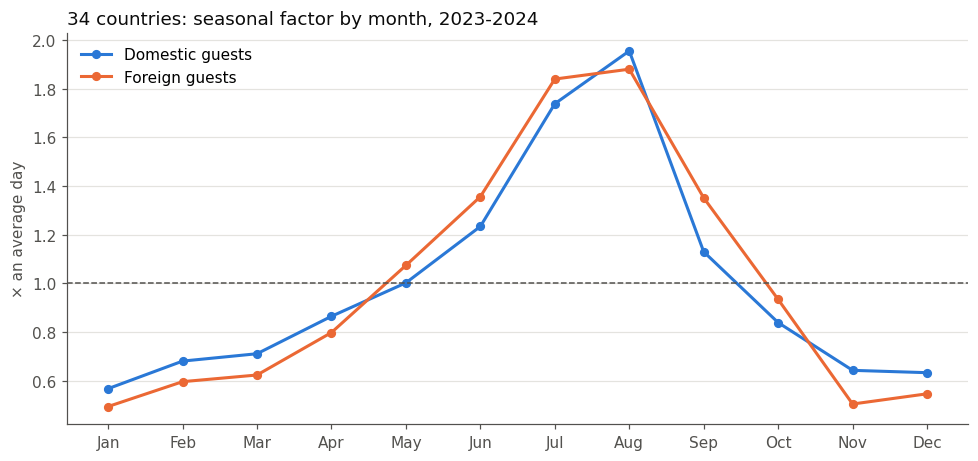

June-August share of the year's daily nights: foreign 42%, domestic 41% (an even year: 25%)


In [11]:
m = NPD[NPD.index.get_level_values("NUTSCode").map(REG["NUTSLevel"]) ==
        0].groupby(level=["ResidenceCountry", "Year"]).sum()
m = (12 * m.div(m.sum(axis=1), axis=0)).groupby(
    level="ResidenceCountry").mean()  # seasonal factors
display(m.round(2))
fig, ax = plt.subplots(figsize=(9, 4.3), dpi=110)
for r in ["Domestic", "Foreign"]:
    ax.plot(range(12),
            m.loc[r].values,
            color=COLOR[r],
            lw=2,
            marker="o",
            ms=5,
            label=f"{r} guests")
ax.axhline(1, color=MUTED, lw=1, ls="--")
ax.set_xticks(range(12), SHORT)
style(ax, "34 countries: seasonal factor by month, 2023-2024",
      "× an average day")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()
jja = lambda r: 100 * m.loc[r, ["June", "July", "August"]].sum() / 12
print(
    f"June-August share of the year's daily nights: foreign {jja('Foreign'):.0f}%, domestic {jja('Domestic'):.0f}% (an even year: 25%)"
)

## How seasonal is foreign demand in each country and region, 2023-2024 profiles

From here on, each region's year is its **2023–2024 average profile**: the share of the year's nights per day in each month, averaged over the two years so that neither year dominates (where only one year is usable — Utrecht, Zuid-Holland, Iceland — that year).

> **Gini index** - the main seasonality measure for this analysis.
> Estimates how unequally the nights are spread over the 12 months.
> *Formula:* twice the covariance between each month's nights and its rank (1 = quietest, 12 = busiest), divided by 12 × the average month.
> *Read:* 0 = every month equal; 0.917 = all nights in one month. 
> It is the standard index in tourism research, measuring how concentrated demand is in time (the pressure on accommodation, transport and staff). 

In [12]:
def gini(y):
    """Gini index of 12 values: 2 cov(y, rank) / (12 mean)."""
    r = np.empty(12)
    r[np.argsort(y, kind="stable")] = np.arange(1, 13)
    return 2 * np.mean((y - y.mean()) * (r / 12 - (r / 12).mean())) / y.mean()


def s_r(y):
    """S_R: least effort to flatten the year, months on a circle (used from 'One season or two?' on)."""
    d = np.cumsum(y - y.mean())
    return np.abs(d - np.median(d)).sum() / (3 * y.sum())


ok_ = NPD[USABLE.reindex(NPD.index, fill_value=False)]
share = ok_.div(ok_.sum(axis=1), axis=0)
PROF = share.groupby(
    level=["NUTSCode", "ResidenceCountry"]).mean()  # 2023-2024 average profile
FAC = 12 * PROF  # seasonal factors
ix = pd.DataFrame(
    {
        "Gini": [gini(r) for r in PROF.to_numpy()],
        "SR": [s_r(r) for r in PROF.to_numpy()],
        "PeakMonth": PROF.idxmax(axis=1),
        "QuietestMonth": PROF.idxmin(axis=1)
    },
    index=PROF.index)
ix["Nights"], ix["LowReliability"] = NIGHTS_AVG, LOWREL
ix = ix.join(REG, on="NUTSCode")
sel = lambda guest, level=2: ix.xs(guest, level="ResidenceCountry").loc[
    lambda x: x["NUTSLevel"] == level]
fo, do, to = sel("Foreign"), sel("Domestic"), sel("Total")
print(
    f"NUTS 2 regions with a usable profile: all guests {len(to)}, foreign {len(fo)}, domestic {len(do)}"
)

NUTS 2 regions with a usable profile: all guests 268, foreign 265, domestic 264


### Countries: ranked by the Gini index of foreign nights

,rank,Gini,Gini domestic,Gini all guests,PeakMonth
Country,,,,,
Croatia,1,0.611,0.392,0.591,August
Bulgaria,2,0.528,0.255,0.399,August
Greece,3,0.526,0.290,0.487,August
Albania,4,0.451,0.395,0.431,August
Cyprus,5,0.345,0.303,0.341,August
Slovenia,6,0.342,0.144,0.284,August
Norway,7,0.333,0.195,0.234,July
Denmark,8,0.323,0.246,0.275,August
Sweden,9,0.312,0.222,0.244,July


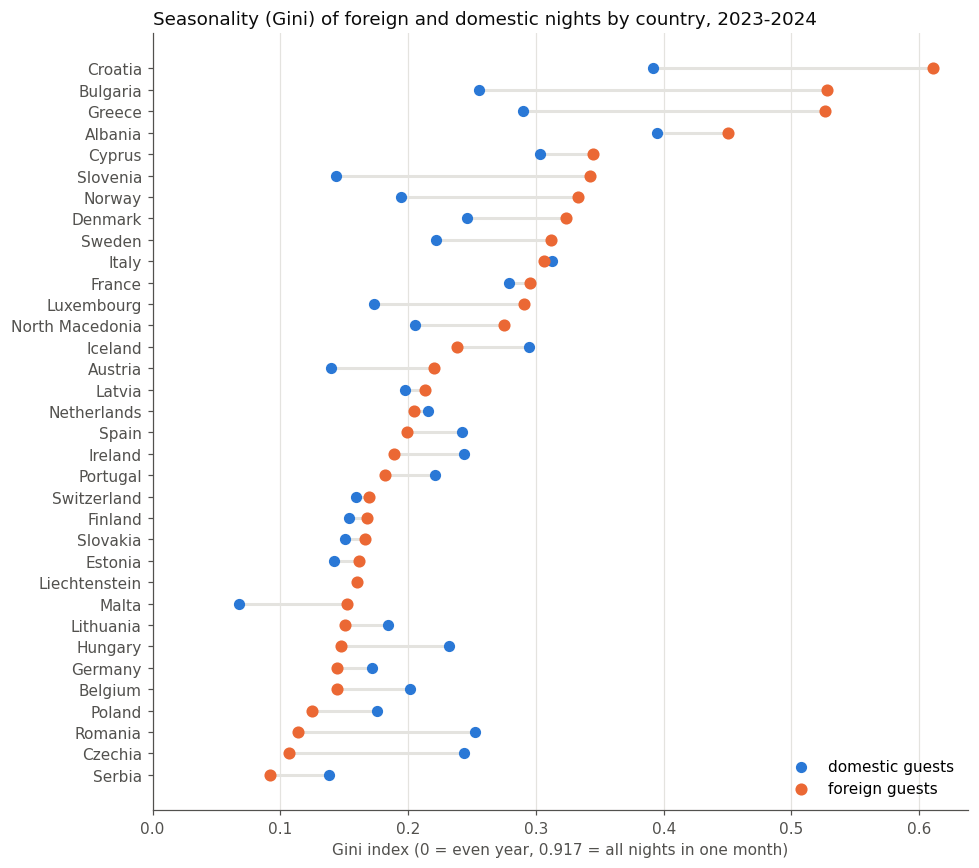

In [13]:
cr = sel("Foreign", 0).set_index("Country")[["Gini", "PeakMonth"]]
cr["rank"] = cr["Gini"].rank(ascending=False).astype(int)
cr["Gini domestic"] = sel("Domestic", 0).set_index("Country")["Gini"]
cr["Gini all guests"] = sel("Total", 0).set_index("Country")["Gini"]
cr = cr.sort_values("rank")
display(cr[["rank", "Gini", "Gini domestic", "Gini all guests",
            "PeakMonth"]].round(3))
fig, ax = plt.subplots(figsize=(9, 8), dpi=110)
y_ = np.arange(len(cr))[::-1]
ax.hlines(y_, cr["Gini domestic"], cr["Gini"], color=GRIDC, lw=2, zorder=1)
ax.scatter(cr["Gini domestic"],
           y_,
           s=40,
           color=COLOR["Domestic"],
           label="domestic guests",
           zorder=3)
ax.scatter(cr["Gini"],
           y_,
           s=48,
           color=COLOR["Foreign"],
           label="foreign guests",
           zorder=4)
ax.set_yticks(y_, cr.index)
ax.set_xlim(0, None)
style(
    ax,
    "Seasonality (Gini) of foreign and domestic nights by country, 2023-2024")
ax.set_xlabel("Gini index (0 = even year, 0.917 = all nights in one month)",
              color=MUTED)
ax.grid(axis="x", color=GRIDC)
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

### Regions: the most and least seasonal foreign demand

Top and bottom 12 NUTS-2 regions by the Gini index of foreign nights. *LowReliability* marks Eurostat's `u` flag.

In [14]:
cols = [
    "Region", "Country", "Gini", "PeakMonth", "QuietestMonth", "LowReliability"
]
print("Most seasonal:")
display(fo.nlargest(12, "Gini")[cols].round(3).reset_index(drop=True))
print("Least seasonal:")
display(fo.nsmallest(12, "Gini")[cols].round(3).reset_index(drop=True))
print(
    f"Median NUTS-2 region: Gini {fo['Gini'].median():.3f} (foreign), {to['Gini'].median():.3f} (all guests)"
)

Most seasonal:


,Region,Country,Gini,PeakMonth,QuietestMonth,LowReliability
0,Yugoiztochen,Bulgaria,0.691,August,December,False
1,Severoiztochen,Bulgaria,0.642,August,January,False
2,Jadranska Hrvatska,Croatia,0.627,August,January,False
3,Corse,France,0.624,August,February,True
4,"Anatoliki Makedonia, Thraki",Greece,0.615,August,January,False
5,Voreio Aigaio,Greece,0.599,August,January,False
6,Ionia Nisia,Greece,0.593,August,January,False
7,Veri,Albania,0.584,August,February,False
8,Thessalia,Greece,0.583,August,January,False
9,Bretagne,France,0.579,August,January,False


Least seasonal:


,Region,Country,Gini,PeakMonth,QuietestMonth,LowReliability
0,Podkarpackie,Poland,0.036,July,December,False
1,Canarias,Spain,0.045,February,May,False
2,Région de Bruxelles-Capitale/Brussels Hoofdste...,Belgium,0.049,July,January,False
3,Bucureşti-Ilfov,Romania,0.050,September,January,False
4,Región de Murcia,Spain,0.062,October,May,False
5,Darmstadt,Germany,0.066,June,February,False
6,Łódzkie,Poland,0.080,July,December,False
7,Região Autónoma da Madeira,Portugal,0.080,August,January,False
8,Comunidad de Madrid,Spain,0.080,October,January,False
9,Severozápad,Czechia,0.082,August,January,False


Median NUTS-2 region: Gini 0.234 (foreign), 0.206 (all guests)


### Map: amplitude classes of foreign demand

> **Amplitude class** shows how *strong* the seasonal swing is: how far the busy months rise above an average month, and the quiet months fall below it. It says nothing about *when* in the year this happens; the timing is described by the season pattern (next section).
> It is the Gini index in three bands: *Low* under 0.17, *Medium* 0.17–0.33, *High* 0.33 or more (cut-offs at the Gini values that split the regions’ foreign demand into three roughly equal groups, 0.171 and 0.325, rounded).
> *Read (typical foreign demand, median region of each class):*
>
> | Class | Busiest month | Quietest month | Two busiest months |
> |---|---|---|---|
> | Low | 1.4 × an average month | 0.65 × | 23% of the year's nights |
> | Medium | 1.8 × | 0.43 × | 29% |
> | High | 2.6 × | 0.21 × | 41% |

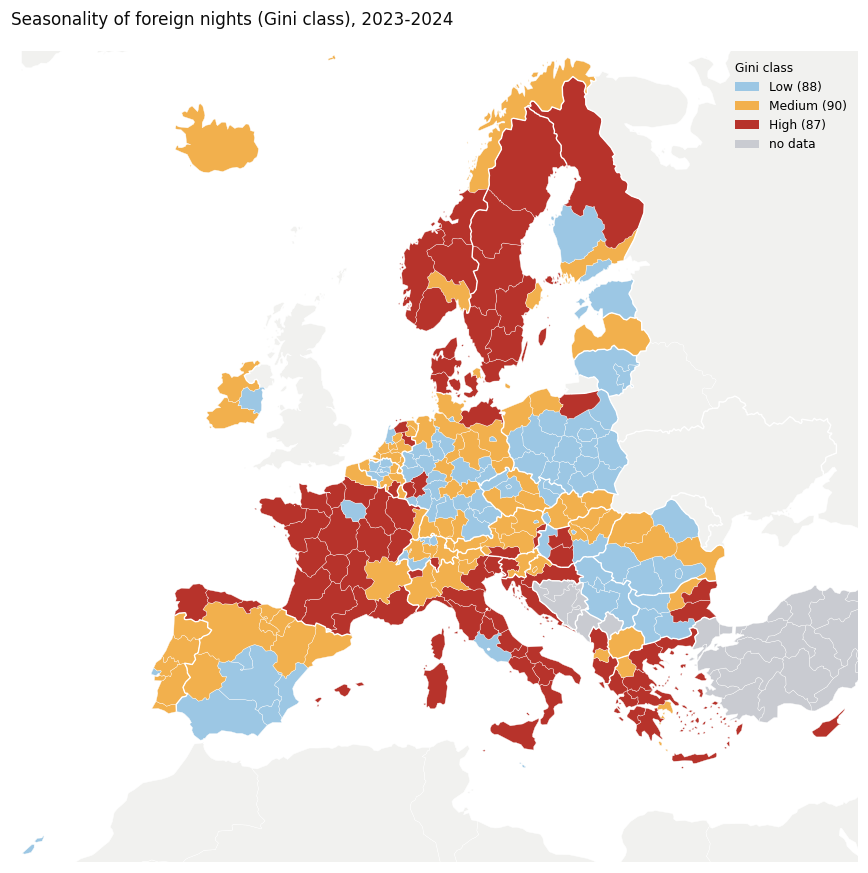

not on this map (Azores, Madeira, French overseas regions): ['FRY2', 'FRY4', 'PT20', 'PT30']


In [15]:
AMP = ["Low", "Medium", "High"]
ACOLOR = {"Low": "#9cc7e4", "Medium": "#f2b04d", "High": "#b7332b"}
ix["AmplitudeClass"] = pd.cut(ix["Gini"], [0, 0.17, 0.33, 1.01],
                              right=False,
                              labels=AMP)
fo, do, to = sel("Foreign"), sel("Domestic"), sel("Total")
region_map({k: ACOLOR[v]
            for k, v in fo["AmplitudeClass"].items()},
           [(f"{a} ({(fo['AmplitudeClass'] == a).sum()})", ACOLOR[a])
            for a in AMP],
           "Seasonality of foreign nights (Gini class), 2023-2024",
           "Gini class")

### One season or two? S_R and the S_R ÷ Gini ratio

The Gini index treats the months as an unordered set: a ski-and-summer region and a coastal region with the same busy and quiet months score the same, although the first has two short gaps and the second one long closure. A second index tells them apart.

> **S_R** (Lo Magno, Ferrante & De Cantis 2017) estimates how much the year would have to change to become perfectly even.
> *Idea:* imagine moving nights from busy to quiet months until every month is equal; S_R is the least total effort, where moving nights one month along the calendar costs 1. December and January are neighbours, so the calendar is a circle.
> *Formula:* with d = running total of (month's share − 1/12) from January, S_R = Σ |d − median(d)| ÷ 3. *Read:* 0 = every month equal, 1 = all nights in one month.
>
> **Spread ratio = S_R ÷ Gini** shows whether the busy months are together or split into separate seasons.
> *Read:* for any year with **one** season — short or long, in summer or around New Year — S_R ≈ Gini, so the ratio is about 1. When the busy months are split, every quiet month lies near a busy one, S_R drops and the ratio falls (ski + summer ≈ 0.55).
> *Classes:* **one season** 0.9 or more; **main + secondary season** 0.6–0.9; **two seasons** under 0.6; **no clear season** when the year is nearly flat (Gini under 0.15).

,Foreign,Domestic,Total
SeasonCount,,,
One season,169,154,167
Main + secondary season,19,14,14
Two seasons,11,9,10
No clear season,66,87,77


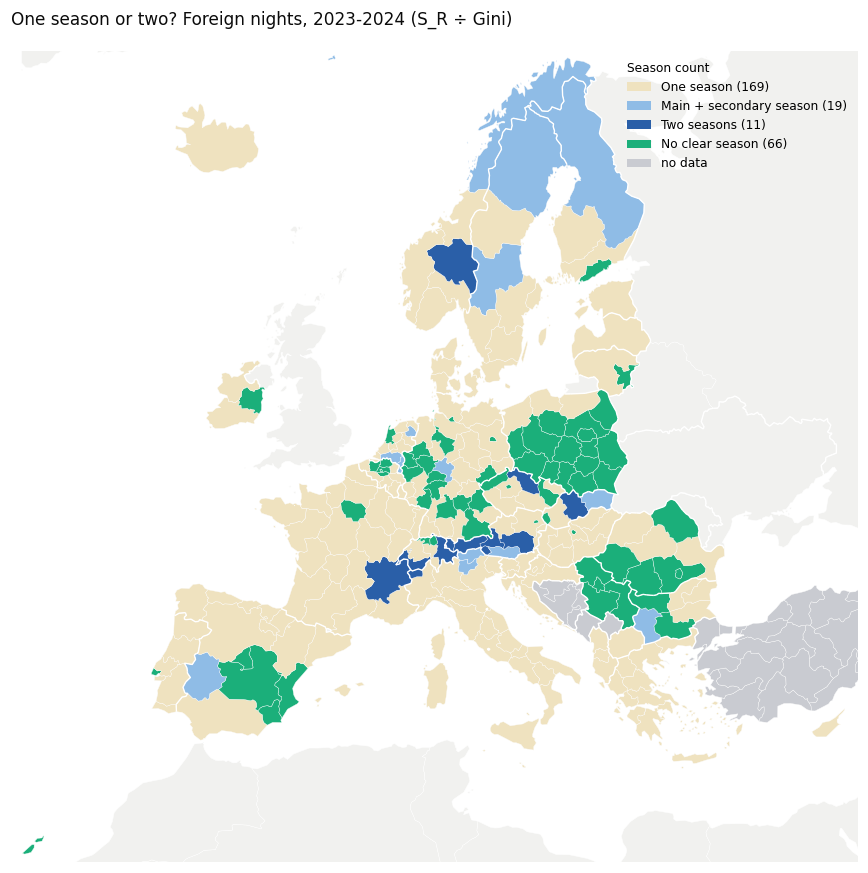

not on this map (Azores, Madeira, French overseas regions): ['FRY2', 'FRY4', 'PT20', 'PT30']

Foreign demand split into two seasons, or a main and a secondary season:


,Region,Country,Gini,SR,SpreadRatio,PeakMonth,QuietestMonth
0,Severovýchod,Czechia,0.223,0.107,0.479,February,November
1,Vorarlberg,Austria,0.270,0.137,0.509,February,November
2,Ostschweiz,Switzerland,0.260,0.133,0.510,August,November
3,Tirol,Austria,0.276,0.142,0.515,February,November
4,Salzburg,Austria,0.292,0.152,0.520,February,November
5,Rhône-Alpes,France,0.283,0.150,0.532,July,November
6,Steiermark,Austria,0.255,0.141,0.551,August,November
7,Stredné Slovensko,Slovakia,0.238,0.133,0.558,July,November
8,Région lémanique,Switzerland,0.159,0.092,0.574,August,November
9,Valle d’Aosta/Vallée d’Aoste,Italy,0.358,0.212,0.593,February,November


In [16]:
SEASONS = [
    "One season", "Main + secondary season", "Two seasons", "No clear season"
]
SCOLOR = {
    "One season": "#efe2bf",
    "Main + secondary season": "#8fbce6",
    "Two seasons": "#2a5fa8",
    "No clear season": "#1baf7a"
}
ix["SpreadRatio"] = ix["SR"] / ix["Gini"]
ix["SeasonCount"] = pd.Categorical(np.select(
    [ix["Gini"] < 0.15, ix["SpreadRatio"] >= 0.9, ix["SpreadRatio"] >= 0.6],
    ["No clear season", "One season", "Main + secondary season"],
    "Two seasons"),
                                   categories=SEASONS)
fo, do, to = sel("Foreign"), sel("Domestic"), sel("Total")
display(
    pd.DataFrame({
        g: sel(g)["SeasonCount"].value_counts().reindex(SEASONS)
        for g in ["Foreign", "Domestic", "Total"]
    }))
region_map({k: SCOLOR[v]
            for k, v in fo["SeasonCount"].items()},
           [(f"{s} ({(fo['SeasonCount'] == s).sum()})", SCOLOR[s])
            for s in SEASONS],
           "One season or two? Foreign nights, 2023-2024 (S_R ÷ Gini)",
           "Season count")
cols = [
    "Region", "Country", "Gini", "SR", "SpreadRatio", "PeakMonth",
    "QuietestMonth"
]
print()
print(
    "Foreign demand split into two seasons, or a main and a secondary season:")
display(fo[fo["SeasonCount"].isin(
    SEASONS[1:3])].sort_values("SpreadRatio")[cols].round(3).reset_index(
        drop=True))

### A crowded peak or an empty off-season?

The Gini index gives the same value to a year with one crowded month and a year with one empty month, but the two call for different policies. Two simple measures separate them:

> **Seasonality indicator** (Lundtorp 2001) = average day ÷ peak-month day. 1 = flat; low = a sharp peak.
> **Peak-to-trough ratio** = peak month ÷ quietest month. High = a deep off-season, empty = a month has no nights.

A table below illustrates this. The Greek islands have ratios of 200–1,500: their problem is above all an empty winter. Other highly seasonal regions sit around 6–7: a strong summer, but their off-season isn't empty.

In [17]:
X = PROF.to_numpy()
ix["SeasonalityIndicator"] = X.mean(axis=1) / X.max(axis=1)
ix["PeakTroughRatio"] = (PROF.max(axis=1) /
                         PROF.min(axis=1)).where(PROF.min(axis=1) > 0)
fo, do, to = sel("Foreign"), sel("Domestic"), sel("Total")
hi = fo[fo["AmplitudeClass"] == "High"]
print(
    f"High-Gini regions ({len(hi)}): median seasonality indicator {hi['SeasonalityIndicator'].median():.2f}, "
    f"median peak-to-trough ratio {hi['PeakTroughRatio'].median():.0f}")
display(
    hi.sort_values("PeakTroughRatio", ascending=False)[[
        "Region", "Gini", "SeasonalityIndicator", "PeakTroughRatio",
        "PeakMonth", "QuietestMonth"
    ]].iloc[np.r_[0:5, -5:0]].round(2).reset_index(drop=True))

High-Gini regions (87): median seasonality indicator 0.38, median peak-to-trough ratio 12


,Region,Gini,SeasonalityIndicator,PeakTroughRatio,PeakMonth,QuietestMonth
0,Ionia Nisia,0.59,0.35,1504.16,August,January
1,Notio Aigaio,0.54,0.41,367.25,July,January
2,Kriti,0.53,0.41,202.01,August,January
3,Yugoiztochen,0.69,0.26,193.63,August,December
4,Corse,0.62,0.28,186.40,August,February
5,Zahodna Slovenija,0.38,0.39,7.19,August,November
6,Östra Mellansverige,0.36,0.33,7.18,July,January
7,Lorraine,0.34,0.43,6.68,August,November
8,Sydsverige,0.33,0.39,6.12,July,January
9,Burgenland,0.35,0.46,5.63,June,February


## What seasonal patterns are there?

> **Season pattern** (shape) and **amplitude class** (size, low/medium/high Gini), after Ferrante, Lo Magno & De Cantis (2018): classify the shape of the year first, measure its size separately.
>
> 1. A nearly flat year (Gini under 0.15) is **Year-round**: its shape is mostly noise.
> 2. For the others only the **shape** is kept: each month's deviation from an average day (factor − 1), scaled so the deviations of one region have unit length. A mild and a sharp summer peak with the same timing then look alike.
> 3. The foreign profiles are grouped into **4** shape groups by Ward's hierarchical clustering.
> 4. Each group is named from its average profile: *Winter + summer seasons* or *Winter season* if December–February is above average, otherwise *Short summer peak* (4 or fewer busy months) or *Long summer season* (5 or more).
> 5. Every profile — foreign, domestic, all guests — takes the pattern of the nearest group average, so the labels mean the same for each guest group.

In [18]:
PATTERNS = [
    "Short summer peak", "Long summer season", "Winter + summer seasons",
    "Winter season", "Year-round"
]
PCOLOR = {
    "Short summer peak": "#eb6834",
    "Long summer season": "#eda100",
    "Winter + summer seasons": "#2a78d6",
    "Winter season": "#6b4fbb",
    "Year-round": "#1baf7a"
}
dev = FAC - 1
UNIT = dev.div(np.sqrt((dev**2).sum(axis=1)), axis=0)  # shape only
seasonal = ix["Gini"] >= 0.15
base = [
    k for k in UNIT.index
    if k[1] == "Foreign" and REG.at[k[0], "NUTSLevel"] == 2 and seasonal[k]
]
groups = fcluster(linkage(UNIT.loc[base].to_numpy(), method="ward"), 4,
                  "maxclust")


def name_of(c):
    if c[["December", "January", "February"]].mean() >= 1:
        return "Winter + summer seasons" if c[
            ["July", "August"]].mean() >= 1 else "Winter season"
    return "Short summer peak" if (c >= 1).sum() <= 4 else "Long summer season"


names = FAC.loc[base].groupby(groups).mean().apply(name_of, axis=1)
centres = UNIT.loc[base].groupby(names.reindex(
    groups).to_numpy()).mean()  # average shape of each named pattern
nearest = ((UNIT[seasonal].to_numpy()[:, None, :] -
            centres.to_numpy()[None])**2).sum(axis=2).argmin(axis=1)
ix["SeasonPattern"] = pd.Categorical(pd.Series(
    centres.index[nearest],
    index=UNIT.index[seasonal]).reindex(ix.index).fillna("Year-round"),
                                     categories=PATTERNS)
fo, do, to = sel("Foreign"), sel("Domestic"), sel("Total")
print("foreign NUTS 2 regions by pattern:",
      fo["SeasonPattern"].value_counts().reindex(PATTERNS).to_dict())

foreign NUTS 2 regions by pattern: {'Short summer peak': 91, 'Long summer season': 92, 'Winter + summer seasons': 14, 'Winter season': 2, 'Year-round': 66}


### Five shapes, sized separately

For each shape: 
* how many NUTS-2 regions have it for foreign guests;
* its typical Gini and spread of amplitude;
* its largest regions
* how much more often than average its regions are coastal, island, inland mountain, rural or urban (× = ratio to the share among all regions).

,regions,Gini median,amplitude Low/Med/High,largest (foreign nights),coastal ×,island ×,inland mountain ×,rural ×,urban ×
Short summer peak,91,0.375,9/28/54,"Jadranska Hrvatska, Kentriki Makedonia, Emilia...",1.2,0.5,0.5,1.5,0.4
Long summer season,92,0.264,11/51/30,"Illes Balears, Cataluña, Veneto",1.3,1.8,1.0,0.9,1.3
Winter + summer seasons,14,0.258,2/10/2,"Tirol, Provincia Autonoma di Bolzano/Bozen, Sa...",0.0,0.0,6.3,0.5,0.7
Winter season,2,0.329,0/1/1,"Pohjois- ja Itä-Suomi, Martinique",2.0,7.0,0.0,0.0,1.5
Year-round,66,0.115,66/0/0,"Canarias, Ile de France, Comunitat Valenciana",0.5,0.6,0.6,0.6,1.6


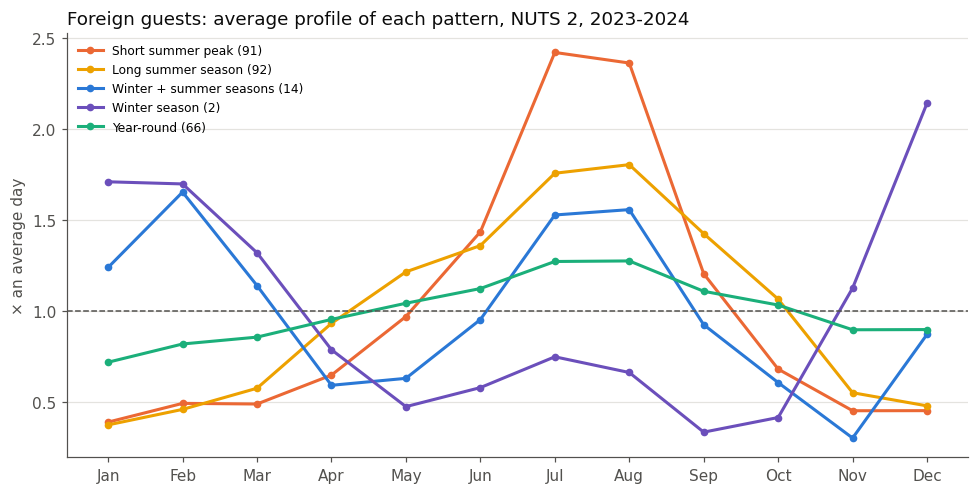

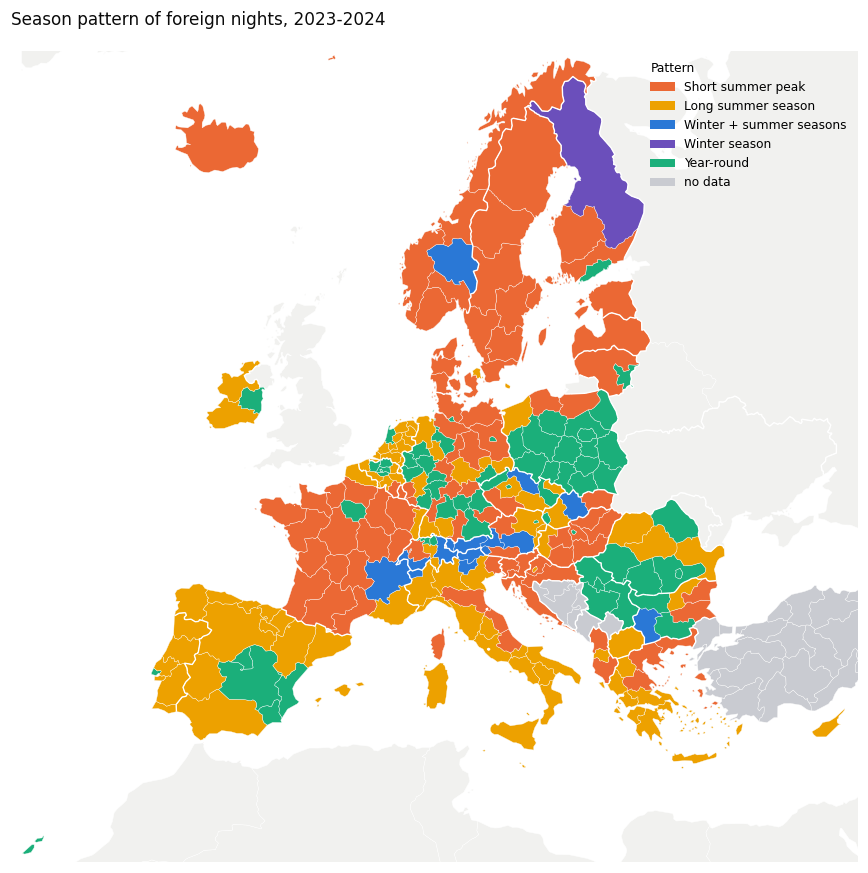

not on this map (Azores, Madeira, French overseas regions): ['FRY2', 'FRY4', 'PT20', 'PT30']


In [19]:
GEO_TYPES = {
    "coastal": fo["PrcCoastal"] >= 50,
    "island": fo["PrcIsland"] >= 50,
    "inland mountain": fo["PrcInlandMountain"] >= 50,
    "rural": fo["PrcRural"] >= 50,
    "urban": fo["PrcRural"] <= 20
}
rows = {}
for p in PATTERNS:
    m_ = fo["SeasonPattern"] == p
    rows[p] = {
        "regions":
        int(m_.sum()),
        "Gini median":
        round(fo.loc[m_, "Gini"].median(), 3),
        "amplitude Low/Med/High":
        "/".join(
            str(int((fo.loc[m_, "AmplitudeClass"] == a).sum())) for a in AMP),
        "largest (foreign nights)":
        ", ".join(fo[m_].nlargest(3, "Nights")["Region"]),
        **{
            f"{g} ×": round(s[m_].mean() / s.mean(), 1)
            for g, s in GEO_TYPES.items()
        }
    }
display(pd.DataFrame(rows).T)
fk = FAC.xs("Foreign", level="ResidenceCountry").reindex(fo.index)
fig, ax = plt.subplots(figsize=(9, 4.6), dpi=110)
for p in PATTERNS:
    ax.plot(range(12),
            fk[fo["SeasonPattern"] == p].mean().values,
            color=PCOLOR[p],
            lw=2,
            marker="o",
            ms=4,
            label=f"{p} ({(fo['SeasonPattern'] == p).sum()})")
ax.axhline(1, color=MUTED, lw=1, ls="--")
ax.set_xticks(range(12), SHORT)
style(ax, "Foreign guests: average profile of each pattern, NUTS 2, 2023-2024",
      "× an average day")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()
region_map({k: PCOLOR[v]
            for k, v in fo["SeasonPattern"].items()},
           [(p, PCOLOR[p]) for p in PATTERNS],
           "Season pattern of foreign nights, 2023-2024", "Pattern")

### Do foreign and domestic guests share the same pattern?

The patterns are typical shapes rather than sharp categories: *Short summer peak* and the two winter patterns are distinct, while *Long summer season* is the broad middle (89% of regions keep their foreign pattern from 2023 to 2024).

In [20]:
x_ = pd.crosstab(do["SeasonPattern"].reindex(fo.index).rename("domestic"),
                 fo["SeasonPattern"].rename("foreign")).reindex(
                     index=PATTERNS, columns=PATTERNS)
print(
    "pattern of domestic (rows) and foreign (columns) guests in the same region:"
)
display(x_)
print(
    f"same pattern for both guest groups in {np.trace(x_.fillna(0).to_numpy()) / x_.to_numpy().sum():.0%} of regions"
)

pattern of domestic (rows) and foreign (columns) guests in the same region:


foreign,Short summer peak,Long summer season,Winter + summer seasons,Winter season,Year-round
domestic,,,,,
Short summer peak,55,45,2,1,15
Long summer season,15,24,0,0,7
Winter + summer seasons,2,0,9,0,0
Winter season,0,1,0,1,0
Year-round,18,22,3,0,44


same pattern for both guest groups in 50% of regions


## Do foreign guests sharpen or smooth the regional season?

### Today's timing: three classes

> **Foreign timing effect** estimates whether the region's year would be more or less seasonal if foreign guests came in the same months as domestic guests.
> *Formula:* Gini of all nights − Gini of (domestic nights + foreign nights spread like the domestic ones), on nights per day.
> *Read:* positive = foreign timing **sharpens** the season; negative = it **smooths** it.
> *Classes:* **Sharpens** or **Smooths** when the 2023–2024 effect is beyond ±0.01 Gini points (about a twentieth of a typical region's Gini, and larger than the year-to-year noise) **and** has the same sign in 2023 and in 2024; otherwise **No clear effect**.
>
> It compares today's demand with a what-if. It is not a causal effect.

Both guest groups need a usable series in the same year.

264 NUTS 2 regions with usable domestic and foreign series


,regions
ForeignTimingClass,
Smooths,50
No clear effect,89
Sharpens,125


Median effect: +0.006 Gini points (median region Gini 0.206); weighted by all nights: +0.016


,regions,median_effect,sharpens,smooths
ForeignGroup,,,,
Mainly domestic,164,0.002,0.354,0.165
Mixed,70,0.018,0.629,0.243
Mainly foreign,30,0.079,0.767,0.200


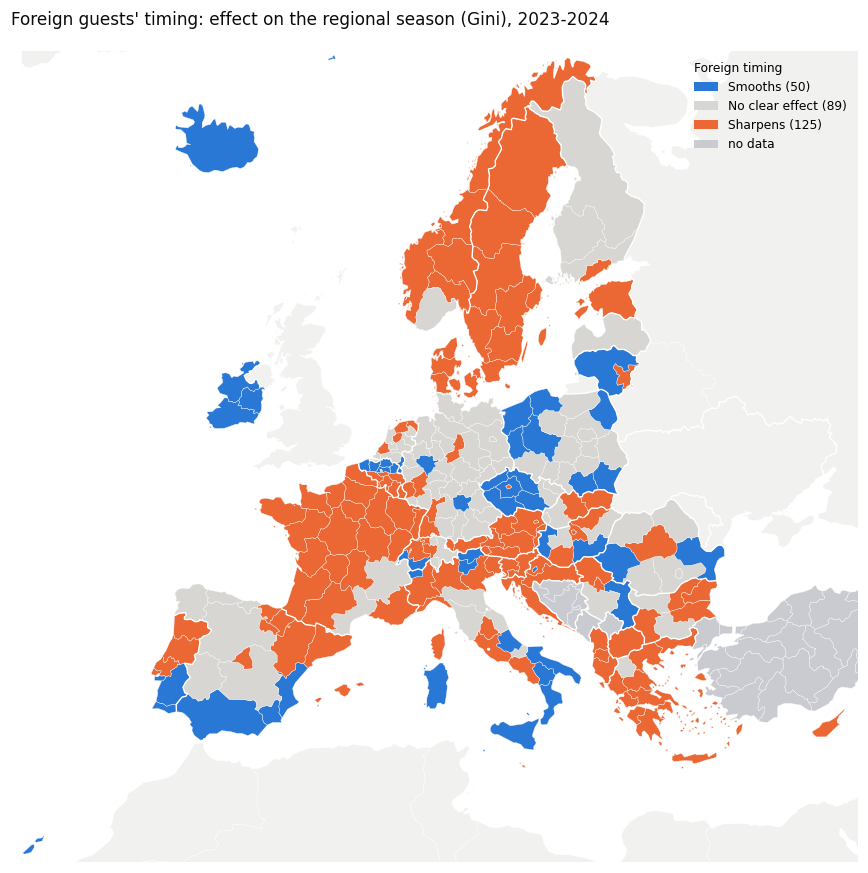

not on this map (Azores, Madeira, French overseas regions): ['FRY2', 'FRY4', 'PT20', 'PT30']


In [21]:
FCLASS = ["Smooths", "No clear effect", "Sharpens"]
FCOLOR = {
    "Smooths": "#2a78d6",
    "No clear effect": "#d7d6d2",
    "Sharpens": "#eb6834"
}
DOM, FOR = NPD.xs("Domestic",
                  level="ResidenceCountry"), NPD.xs("Foreign",
                                                    level="ResidenceCountry")
ok = USABLE.xs("Domestic", level="ResidenceCountry") & USABLE.xs(
    "Foreign", level="ResidenceCountry").reindex(DOM.index, fill_value=False)
ok = ok[ok.index.get_level_values("NUTSCode").map(REG["NUTSLevel"]) == 2]
d_y, f_y = DOM.loc[ok[ok].index], FOR.loc[
    ok[ok].index]  # region x year, both groups usable
d_avg, f_avg = d_y.groupby(level="NUTSCode").mean(), f_y.groupby(
    level="NUTSCode").mean()


def timing_effect(d, f):
    return gini(d + f) - gini(d + f.sum() * d / d.sum())


eff_y = pd.Series(
    [timing_effect(d, f) for d, f in zip(d_y.to_numpy(), f_y.to_numpy())],
    index=d_y.index).unstack("Year")
fe = pd.DataFrame(
    {
        "TimingEffect": [
            timing_effect(d, f)
            for d, f in zip(d_avg.to_numpy(), f_avg.to_numpy())
        ]
    },
    index=d_avg.index)
stable = (np.sign(eff_y[2023]) == np.sign(eff_y[2024])) | eff_y.isna().any(
    axis=1)  # one usable year: no sign rule
fe["ForeignTimingClass"] = pd.Categorical(
    np.select([(fe["TimingEffect"] > 0.01) & stable,
               (fe["TimingEffect"] < -0.01) & stable], ["Sharpens", "Smooths"],
              "No clear effect"),
    categories=FCLASS)
fe = fe.join(reg[["Region", "Country", "PrcForeign", "ForeignGroup",
                  "Nights"]])
fe["Gini domestic"], fe["Gini foreign"] = do["Gini"], fo["Gini"]
print(f"{len(fe)} NUTS 2 regions with usable domestic and foreign series")
display(fe["ForeignTimingClass"].value_counts().reindex(FCLASS).rename(
    "regions").to_frame())
print(
    f"Median effect: {fe['TimingEffect'].median():+.3f} Gini points (median region Gini {to['Gini'].median():.3f}); "
    f"weighted by all nights: {np.average(fe['TimingEffect'], weights=fe['Nights']):+.3f}"
)
display(
    fe.groupby("ForeignGroup",
               observed=False).agg(regions=("TimingEffect", "size"),
                                   median_effect=("TimingEffect", "median"),
                                   sharpens=("ForeignTimingClass", lambda s:
                                             (s == "Sharpens").mean()),
                                   smooths=("ForeignTimingClass", lambda s:
                                            (s == "Smooths").mean())).round(3))
region_map(
    {k: FCOLOR[v]
     for k, v in fe["ForeignTimingClass"].items()},
    [(f"{c} ({(fe['ForeignTimingClass'] == c).sum()})", FCOLOR[c])
     for c in FCLASS],
    "Foreign guests' timing: effect on the regional season (Gini), 2023-2024",
    "Foreign timing")

### What it looks like: domestic, foreign and all guests by class

Average seasonal factors of the regions in each class, and the regions with the largest effects.

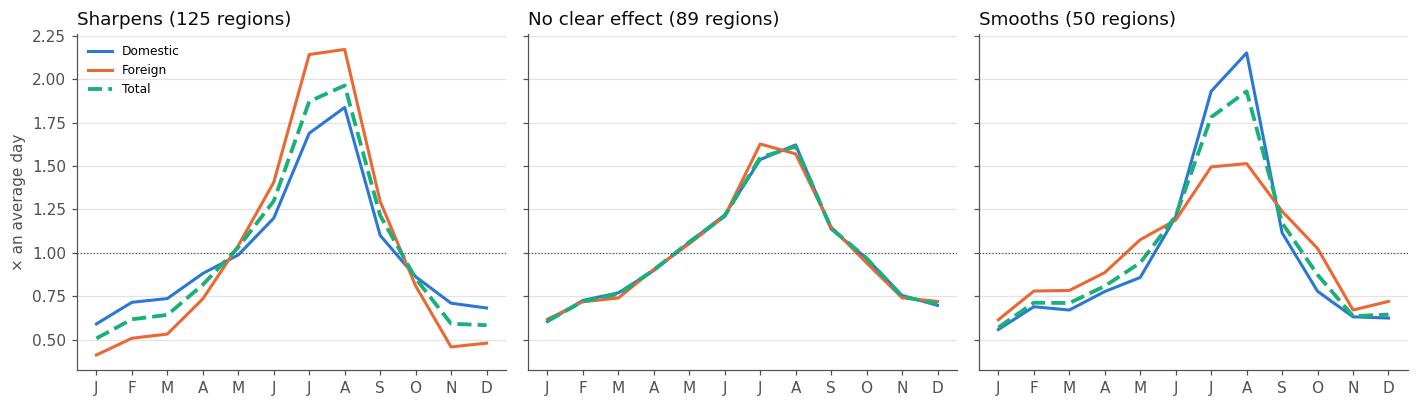

Largest smoothing effects:


,Region,Country,PrcForeign,TimingEffect,Gini domestic,Gini foreign
0,Provincia Autonoma di Bolzano/Bozen,Italy,71.089,-0.201,0.444,0.206
1,Canarias,Spain,87.364,-0.164,0.199,0.045
2,Algarve,Portugal,75.563,-0.139,0.417,0.235
3,Comunitat Valenciana,Spain,53.722,-0.098,0.294,0.121
4,Región de Murcia,Spain,35.104,-0.089,0.254,0.062
5,Provincia Autonoma di Trento,Italy,43.128,-0.080,0.406,0.251
6,Northern and Western,Ireland,62.202,-0.078,0.307,0.202
7,Severozápad,Czechia,48.635,-0.065,0.201,0.082


Largest sharpening effects:


,Region,Country,PrcForeign,TimingEffect,Gini domestic,Gini foreign
0,"Anatoliki Makedonia, Thraki",Greece,73.292,0.243,0.283,0.615
1,Kentriki Makedonia,Greece,78.071,0.223,0.288,0.576
2,Kriti,Greece,94.522,0.217,0.297,0.527
3,Panonska Hrvatska,Croatia,60.162,0.199,0.085,0.443
4,Ipeiros,Greece,53.705,0.161,0.252,0.570
5,Thessalia,Greece,58.886,0.151,0.290,0.583
6,Severoiztochen,Bulgaria,74.729,0.146,0.445,0.642
7,Região Autónoma dos Açores,Portugal,62.256,0.146,0.126,0.367


In [22]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), dpi=110, sharey=True)
for ax, c in zip(axs, ["Sharpens", "No clear effect", "Smooths"]):
    codes = fe.index[fe["ForeignTimingClass"] == c]
    for r in ["Domestic", "Foreign", "Total"]:
        v = FAC.xs(r, level="ResidenceCountry").reindex(codes).mean()
        ax.plot(range(12),
                v.values,
                color=COLOR[r],
                lw=2 if r != "Total" else 2.5,
                ls="-" if r != "Total" else "--",
                label=r)
    ax.axhline(1, color=MUTED, lw=0.8, ls=":")
    ax.set_xticks(range(12), [s[0] for s in SHORT])
    style(ax, f"{c} ({len(codes)} regions)")
axs[0].set_ylabel("× an average day", color=MUTED)
axs[0].legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()
cols = [
    "Region", "Country", "PrcForeign", "TimingEffect", "Gini domestic",
    "Gini foreign"
]
print("Largest smoothing effects:")
display(fe.nsmallest(8, "TimingEffect")[cols].round(3).reset_index(drop=True))
print("Largest sharpening effects:")
display(fe.nlargest(8, "TimingEffect")[cols].round(3).reset_index(drop=True))

### Four types of foreign demand (after Fernández-Morales, Cisneros-Martínez & McCabe 2016)

The three classes describe **today's** timing. Using the same Gini index, these authors ask a different question: would **more** foreign demand lower or raise the region's seasonality? - and **why**.

> **Gini decomposition and relative marginal effect (RME)**
> The region's Gini splits into the contributions of domestic and foreign guests. For foreign guests three numbers matter:
> * **S_F** - foreign share of the region's nights;
> * **G_F** - the Gini of foreign nights alone: how seasonal foreign guests are in themselves;
> * **Γ_F** - the Gini correlation: how far foreign guests' busy months coincide with the region's busy months (1 = same months, 0 = unrelated, negative = opposite).
>
> *Formula:* RME = S_F × (Γ_F × G_F ÷ G − 1), where G is the region's Gini.
> *Read:* RME is the **percentage change in the region's Gini when foreign nights grow by 1%**, with the extra guests coming in the same months as today's foreign guests (every month +1%). Negative = more foreign guests would flatten the year; positive = they would sharpen it.
> *Example:* Bolzano, RME −0.16: 1% more foreign nights lowers its Gini by 0.16% of its value, and 10% more by about 1.4% (0.243 → 0.240). Kriti, RME +0.02: 10% more foreign nights raises its Gini by about 0.2% (0.514 → 0.515).
> The changes are small; what the RME mainly tells is the **direction**. The ±0.02 cut-off sets aside directions so weak that even 10% more foreign nights would move the Gini by less than 0.2%.

| Type | Rule | What it means for policy |
|---|---|---|
| **Flatter foreign demand** | RME ≤ −0.02 and G_F below the region's G | foreign guests spread their stays more evenly — growing them lowers seasonality durably |
| **Off-peak foreign demand** | RME ≤ −0.02 and G_F at or above G | foreign guests are seasonal too, but in the region's quiet months (low Γ_F) - a *compensation* that works only while it offsets the other guests |
| **Neutral foreign demand** | RME between −0.02 and +0.02, or its sign flips between years | little effect either way |
| **Peak-reinforcing foreign demand** | RME ≥ +0.02 | foreign guests come in the region's own peak months — growing them sharpens the season; spreading their stays matters more than adding them |

,regions,% of all nights
ForeignEffectType,,
Flatter foreign demand,54,17.3
Off-peak foreign demand,6,1.5
Neutral foreign demand,64,31.6
Peak-reinforcing foreign demand,140,49.7


Four types (rows) against the three timing classes (columns):


ForeignTimingClass,Smooths,No clear effect,Sharpens
ForeignEffectType,,,
Flatter foreign demand,42,12,0
Off-peak foreign demand,3,3,0
Neutral foreign demand,2,57,5
Peak-reinforcing foreign demand,3,17,120


Foreign group (rows) and type (columns):


ForeignEffectType,Flatter foreign demand,Off-peak foreign demand,Neutral foreign demand,Peak-reinforcing foreign demand
ForeignGroup,,,,
Mainly domestic,37,5,48,74
Mixed,13,1,10,46
Mainly foreign,4,0,6,20


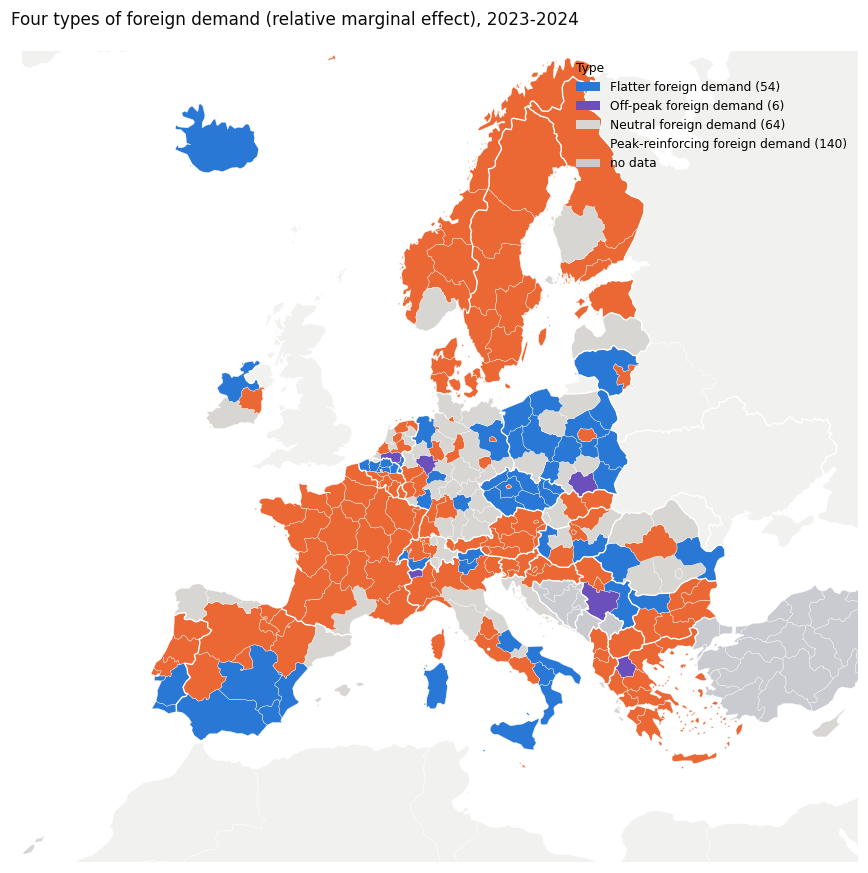

not on this map (Azores, Madeira, French overseas regions): ['FRY2', 'FRY4', 'PT20', 'PT30']


In [23]:
TYPES = [
    "Flatter foreign demand", "Off-peak foreign demand",
    "Neutral foreign demand", "Peak-reinforcing foreign demand"
]
TCOLOR = {
    "Flatter foreign demand": "#2a78d6",
    "Off-peak foreign demand": "#6b4fbb",
    "Neutral foreign demand": "#d7d6d2",
    "Peak-reinforcing foreign demand": "#eb6834"
}


def gini_corr(x, y):
    """Gini correlation of x with y: cov(x, rank of y) / cov(x, rank of x)."""
    rank = lambda v: np.argsort(np.argsort(v, kind="stable"), kind="stable"
                                ) + 1
    return np.cov(x, rank(y), bias=True)[0, 1] / np.cov(x, rank(x),
                                                        bias=True)[0, 1]


def decomposition(d, f):
    y = d + f
    S_F, G_F, G, GC = f.sum() / y.sum(), gini(f), gini(y), gini_corr(f, y)
    return {
        "S_F": S_F,
        "G_F": G_F,
        "G": G,
        "GiniCorrF": GC,
        "RME": S_F * (GC * G_F / G - 1)
    }


rme_y = pd.Series([
    decomposition(d, f)["RME"] for d, f in zip(d_y.to_numpy(), f_y.to_numpy())
],
                  index=d_y.index).unstack("Year")
fe = fe.join(
    pd.DataFrame([
        decomposition(d, f) for d, f in zip(d_avg.to_numpy(), f_avg.to_numpy())
    ],
                 index=d_avg.index))
stable_rme = (np.sign(rme_y[2023]) == np.sign(
    rme_y[2024])) | rme_y.isna().any(axis=1)
fav, unfav = (fe["RME"] < -0.02) & stable_rme, (fe["RME"] > 0.02) & stable_rme
fe["ForeignEffectType"] = pd.Categorical(
    np.select([fav & (fe["G_F"] < fe["G"]), fav, unfav],
              [TYPES[0], TYPES[1], TYPES[3]], TYPES[2]),
    categories=TYPES)
ft = fe["ForeignEffectType"]
display(
    pd.DataFrame({
        "regions":
        ft.value_counts().reindex(TYPES),
        "% of all nights":
        (100 *
         fe.groupby("ForeignEffectType", observed=False)["Nights"].sum() /
         fe["Nights"].sum()).round(1)
    }))
print("Four types (rows) against the three timing classes (columns):")
display(
    pd.crosstab(ft, fe["ForeignTimingClass"]).reindex(index=TYPES,
                                                      columns=FCLASS))
print("Foreign group (rows) and type (columns):")
display(pd.crosstab(fe["ForeignGroup"], ft).reindex(index=FG, columns=TYPES))
region_map(
    {k: TCOLOR[v]
     for k, v in ft.items()}, [(f"{t} ({(ft == t).sum()})", TCOLOR[t])
                               for t in TYPES],
    "Four types of foreign demand (relative marginal effect), 2023-2024",
    "Type")

**Reading the following chart.** RME is negative exactly when Γ_F × G_F < G, i.e. when a region lies below the dashed curve in the chart. Left of the dotted line (G_F < G), foreign demand is flatter than the region's. Right of it, foreign demand is more seasonal but can still be favourable if its busy months are elsewhere (low Γ_F).

**A caveat from the formula.** Where foreign guests are nearly all the nights (S_F > 0.9: the Croatian coast, the Ionian and Aegean islands, Cyprus), the foreign year *is* the region's year, so the RME is close to 0 by construction. *Neutral* there means "foreign guests are the season", not "foreign guests do not matter". The timing effect above is the better guide in those regions.

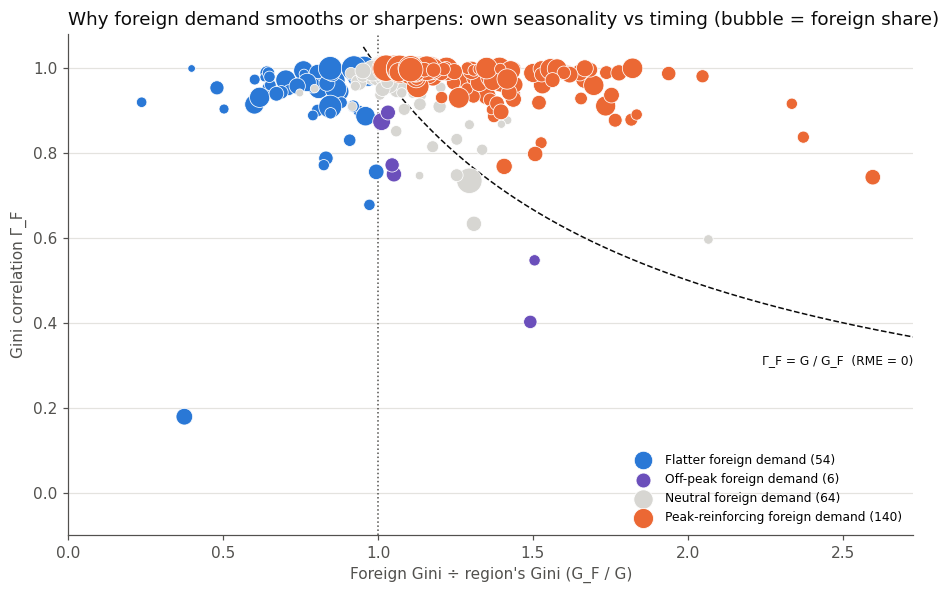

Flatter foreign demand: 54 regions; largest by Gini:


,Region,Country,S_F,G_F,G,GiniCorrF,RME
0,Calabria,Italy,0.191,0.529,0.624,0.986,-0.031
1,Sud-Est,Romania,0.036,0.241,0.605,0.999,-0.021
2,Sardegna,Italy,0.496,0.527,0.548,0.988,-0.024
3,Puglia,Italy,0.322,0.418,0.501,0.964,-0.063
4,Basilicata,Italy,0.174,0.353,0.439,0.900,-0.048
5,Abruzzo,Italy,0.148,0.386,0.438,0.919,-0.028


Off-peak foreign demand: 6 regions; largest by Gini:


,Region,Country,S_F,G_F,G,GiniCorrF,RME
0,Valle d’Aosta/Vallée d’Aoste,Italy,0.404,0.358,0.354,0.874,-0.047
1,Noord-Brabant,Netherlands,0.269,0.221,0.214,0.895,-0.020
2,Dytiki Makedonia,Greece,0.136,0.234,0.155,0.547,-0.024
3,Region Sumadije i Zapadne Srbije,Serbia,0.243,0.133,0.128,0.772,-0.047
4,Małopolskie,Poland,0.291,0.111,0.106,0.750,-0.062
5,Arnsberg,Germany,0.209,0.113,0.075,0.402,-0.084


Neutral foreign demand: 64 regions; largest by Gini:


,Region,Country,S_F,G_F,G,GiniCorrF,RME
0,Jadranska Hrvatska,Croatia,0.922,0.627,0.616,1.000,0.016
1,Ionia Nisia,Greece,0.935,0.593,0.581,1.000,0.018
2,Åland,Finland,0.485,0.536,0.525,0.983,0.002
3,Languedoc-Roussillon,France,0.225,0.548,0.512,0.989,0.013
4,Illes Balears,Spain,0.899,0.476,0.471,0.999,0.007
5,Marche,Italy,0.172,0.426,0.448,0.982,-0.012


Peak-reinforcing foreign demand: 140 regions; largest by Gini:


,Region,Country,S_F,G_F,G,GiniCorrF,RME
0,Yugoiztochen,Bulgaria,0.641,0.691,0.635,1.0,0.057
1,Severoiztochen,Bulgaria,0.747,0.642,0.591,1.0,0.064
2,Corse,France,0.327,0.623,0.568,1.0,0.032
3,Voreio Aigaio,Greece,0.742,0.599,0.567,1.0,0.042
4,Veri,Albania,0.669,0.583,0.539,1.0,0.054
5,Notio Aigaio,Greece,0.921,0.541,0.529,1.0,0.020


In [24]:
x_ = fe["G_F"] / fe["G"]
fig, ax = plt.subplots(figsize=(8.5, 5.5), dpi=110)
for t in TYPES:
    m_ = ft == t
    ax.scatter(x_[m_],
               fe.loc[m_, "GiniCorrF"],
               s=14 + 300 * fe.loc[m_, "S_F"],
               color=TCOLOR[t],
               edgecolor="white",
               lw=0.5,
               label=f"{t} ({m_.sum()})",
               zorder=3)
xx = np.linspace(1 / 1.05, x_.max() * 1.05, 200)
ax.plot(xx, 1 / xx, color=INK, lw=1, ls="--", zorder=2)
ax.text(xx[-1],
        1 / xx[-1] - 0.04,
        "Γ_F = G / G_F  (RME = 0)",
        ha="right",
        va="top",
        fontsize=8,
        color=INK)
ax.axvline(1, color=MUTED, lw=1, ls=":")
ax.set_xlim(0,
            x_.max() * 1.05)
ax.set_ylim(min(-0.1, fe["GiniCorrF"].min() - 0.05), 1.08)
style(
    ax,
    "Why foreign demand smooths or sharpens: own seasonality vs timing (bubble = foreign share)",
    "Gini correlation Γ_F")
ax.set_xlabel("Foreign Gini ÷ region's Gini (G_F / G)", color=MUTED)
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()
cols = ["Region", "Country", "S_F", "G_F", "G", "GiniCorrF", "RME"]
for t in TYPES:
    print(f"{t}: {(ft == t).sum()} regions; largest by Gini:")
    display(fe[ft == t].nlargest(6,
                                 "G")[cols].round(3).reset_index(drop=True))

## What goes with a more seasonal foreign demand?

A linear regression of the Gini index of foreign nights on the region's geography (shares of residents in coastal, rural, island and inland mountain municipalities, 0–1), the volume of foreign nights, and - in some models - the country, so the comparison is between regions of the same country. Uncertainty is clustered by country. Geography shares describe residents, not where guests stay; climate, transport, ski and beach supply and prices are not in the data. **Associations, not causes.**

In [25]:
def ols(y, X, groups):
    """Least squares with country-clustered standard errors and p-values from t with (countries - 1) df."""
    XtX_inv = np.linalg.inv(X.T @ X)
    b = XtX_inv @ X.T @ y
    u = y - X @ b
    g = pd.factorize(groups)[0]
    G, (n, k) = g.max() + 1, X.shape
    meat = sum(
        np.outer(X[g == i].T @ u[g == i], X[g == i].T @ u[g == i])
        for i in range(G))
    se = np.sqrt(
        np.diag(XtX_inv @ meat @ XtX_inv) * G / (G - 1) * (n - 1) / (n - k))
    return b, se, 2 * stats.t.sf(np.abs(b / se), G - 1), 1 - (u @ u) / (
        (y - y.mean())**2).sum()


GEO_SH, NAMES = ["PrcCoastal", "PrcRural", "PrcIsland", "PrcInlandMountain"
                 ], ["coastal", "rural", "island", "inland mountain"]
gs = fo.dropna(subset=GEO_SH)
Z, V = gs[GEO_SH].to_numpy() / 100, np.log10(gs[["Nights"]].to_numpy(float))
D = pd.get_dummies(gs["Country"], drop_first=True, dtype=float).to_numpy()
res = {}
for name, parts in {
        "geography": [Z],
        "geography + volume": [Z, V],
        "geography + country": [Z, D],
        "geography + volume + country": [Z, V, D]
}.items():
    b, se, p, r2 = ols(gs["Gini"].to_numpy(),
                       np.column_stack([np.ones(len(gs))] + parts),
                       gs["Country"].to_numpy())
    row = {
        k: f"{b[1 + j]:+.3f} ± {se[1 + j]:.3f} (p {p[1 + j]:.3f})"
        for j, k in enumerate(NAMES)
    }
    if any(part is V for part in parts):
        row["volume (×10 nights)"] = f"{b[5]:+.3f} ± {se[5]:.3f} (p {p[5]:.3f})"
    res[name] = row | {"R²": round(r2, 2)}
print(
    f"Gini of foreign nights, {len(gs)} NUTS 2 regions; change in Gini from 0% to 100% ± clustered SE:"
)
display(
    pd.DataFrame(res).T.reindex(columns=NAMES +
                                ["volume (×10 nights)", "R²"]).fillna(""))

Gini of foreign nights, 254 NUTS 2 regions; change in Gini from 0% to 100% ± clustered SE:


,coastal,rural,island,inland mountain,volume (×10 nights),R²
geography,+0.212 ± 0.039 (p 0.000),+0.377 ± 0.098 (p 0.001),-0.056 ± 0.041 (p 0.179),+0.027 ± 0.033 (p 0.423),,0.35
geography + volume,+0.191 ± 0.033 (p 0.000),+0.435 ± 0.092 (p 0.000),-0.078 ± 0.041 (p 0.067),+0.006 ± 0.031 (p 0.848),+0.057 ± 0.018 (p 0.003),0.4
geography + country,+0.129 ± 0.040 (p 0.003),+0.374 ± 0.064 (p 0.000),-0.028 ± 0.039 (p 0.475),-0.021 ± 0.036 (p 0.558),,0.66
geography + volume + country,+0.124 ± 0.041 (p 0.005),+0.413 ± 0.072 (p 0.000),-0.033 ± 0.033 (p 0.334),-0.026 ± 0.039 (p 0.501),+0.031 ± 0.017 (p 0.089),0.67


## Conclusions and limitations

1. **Overview.** European tourism is a summer, coastal and August phenomenon: the two busiest months hold 31% of the EU's nights, capitals are the least seasonal regions in most countries.
2. **Size.** Foreign guests account for 47% of nights in tourist accommodation in the 34 countries (2023–2024), concentrated in a few mainly-foreign regions on the Mediterranean, the Adriatic, the islands and the Alps.
3. **Ranking.** Measured by the Gini index, Croatia, Bulgaria, Greece and Albania have the most seasonal foreign demand; Serbia, Czechia, Romania and Poland the least. In the Alps and the Czech and Slovak mountains foreign demand is split into a winter and a summer season (S_R ÷ Gini): the Gini index shows how concentrated their demand is, but their off-season is two short gaps rather than one long closure, so they rank much lower by S_R (Austria 15th by Gini, 31st by S_R).
4. **Patterns.** Foreign demand follows five shapes - long summer, short summer peak, winter + summer, winter only, and year-round - whose size varies widely within each shape. The summer shapes blend into each other.
5. **Foreign guests' effect.** Measured with the same index as the decomposition (Gini), their timing sharpens the regional season more often than it smooths it (125 vs 50 regions), mostly where they are a large share of guests and domestic demand is fairly even. Where foreign guests smooth, it is almost always because their own year is flatter (54 regions), rarely because they fill the region's off-season (6). Growing foreign demand would flatten the season in the first group, and sharpen it in the 140 peak-reinforcing regions - there, spreading foreign stays across the year matters more than adding them.
6. **Geography.** Coastal and rural regions have the most seasonal foreign demand; the link holds within countries.


### Limitations

* **Two years only (2023–2024).** No pre-COVID baseline at NUTS 2 and no long-run change analysis; the 2023–2024 average reduces, but does not remove, one-off events (Easter falls in April 2023 and March 2024).
* **Establishments only.** Countries may exclude establishments with fewer than 10 (in small countries 20) bed places, so small private rentals - often very seasonal - are under-counted, unevenly across countries.
* **Gaps and flags.** Utrecht, Zuid-Holland and Iceland have 2023 only; Liechtenstein's guest groups and three French overseas regions fall below the volume or confidentiality rule; Corse and the overseas regions carry Eurostat's low-reliability flag; Albania's 2023 values are Eurostat estimates.
* **Foreign guests are one group** - the data have no countries of origin.
* **RME near 0 where foreign guests are almost all nights** - the four types are read together with the timing counterfactual.
* **Geography shares describe residents**, not where guests stay; climate, access, ski and beach supply and prices are not in the data.
* **Accounting comparisons and associations, not causal effects.**